# RQ18 — Computational burden versus predictive performance

## Scientific question

**What predictive performance is obtained for the downstream computational burden paid by each model family, and where do simpler learners operating on strong protein representations approach more complex alternatives?**

RQ18 is a **secondary practical analysis**. It does not redefine model quality and does not select a new "winner".

The frozen benchmark recorded runtime/resource metadata precisely so that predictive gain can be considered together with computational burden. The key methodological distinction is:

\[
\boxed{
\text{representation generation}
\neq
\text{downstream model fitting/evaluation}
}
\]

Protein-language-model embeddings are generated once and can be reused by many tasks, R/S conditions, and classifiers. Their extraction time is therefore an **up-front, amortizable representation cost**, not a per-classifier downstream runtime.

RQ18 consequently has two separate layers:

1. **Downstream compute/performance** — the primary comparable analysis.
2. **Representation-generation burden** — reported separately where execution metadata exist.

They are **never silently summed into an end-to-end runtime**.


## Main questions

### Supervised benchmark

1. Which learner/representation combinations have the largest downstream runtime?
2. How strongly does runtime depend on algorithm, representation, R/S, and training-set size?
3. Which combinations most often lie on the **performance/runtime Pareto frontier**?
4. Which combinations are within **0.02 MCC of the best model in the same `task × R × S` cell**?
5. Does `T30 + LR` approach `T30 + MLP/XGB` while requiring less downstream compute?
6. What downstream-runtime premium accompanies `T30−T6` and `T30−Roxy` representation gains?
7. Are the high-cost combinations anticipated by the methodological design actually observed?
8. Where available, which combinations also incur the largest peak-memory burden?

### Positive–unlabeled benchmark

9. What is the runtime multiplier of BaggingPU or Elkan–Noto relative to naive P-vs-U?
10. How much U95 recovery is gained for that additional runtime?
11. Does the one-hot BaggingPU regime identified in RQ15/RQ17 have a different compute/performance trade-off from T30/T6/Roxy?
12. How much more expensive is the broad U universe than the conservative one at matched model settings?

### Representation extraction

13. What were the recorded one-time extraction runtimes for ESM2-T6 and ESM2-T30?
14. How much larger is the T30 extraction burden per processed sequence?
15. Can representation extraction be reported comparably for Roxy/one-hot, or is timing metadata incomplete/non-homogeneous?


## Interpretation contract

- **MCC** remains the primary supervised performance metric.
- **U95 positive recovery** remains the primary PU recognition diagnostic.
- Runtime measurements are environment-specific. They describe the executed benchmark hardware/software context and should not be presented as universal hardware-independent speed.
- Downstream runtime is compared only using the runtime definition actually recorded by the training pipeline.
- Representation extraction runtime is never added to every downstream model run.
- No artificial scalar such as `MCC / seconds` is treated as a universal efficiency score.
- Efficiency is characterized using:
  - paired runtime ratios;
  - paired performance deltas;
  - Pareto non-domination;
  - near-best performance at a fixed MCC tolerance.
- A model within 0.02 MCC of the cell-best is termed **near-best for this sensitivity analysis**, not statistically equivalent.
- Missing optional resource metadata (memory, prediction time, dimensions) remain missing; RQ18 does not manufacture them.
- PU runtime is interpreted together with RQ12–RQ17: high-scoring U remains unlabeled/candidate-like, not confirmed positive.


In [1]:
from pathlib import Path
import json
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 280)
pd.set_option("display.max_rows", 500)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

REP_LABELS = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}

ALG_ORDER = ["LR", "RF", "KNN", "XGB", "MLP"]

PU_METHOD_ORDER = [
    "naive",
    "baggingpu",
    "elkan_noto",
]

NEAR_BEST_MCC_TOL = 0.02

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)

    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/training_supervised").is_dir()
            and (candidate / "results/analysis_pu/stage12a_qc").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root containing "
        "supervised Stage12A/training outputs and PU Stage12A-QC."
    )

ROOT = find_project_root()

SUP_STAGE12A = ROOT / "results/analysis_supervised/stage12a"
SUP_TRAINING = ROOT / "results/training_supervised"

PU_QC = ROOT / "results/analysis_pu/stage12a_qc"
PU_STAGE12B2 = ROOT / "results/analysis_pu/stage12b2"
PU_CACHE = ROOT / "results/analysis_pu/notebook_cache"

REP_ROOT = ROOT / "data/representations"
CACHE_DIR = ROOT / "results/analysis_compute/rq18"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("CACHE_DIR:", CACHE_DIR)


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
CACHE_DIR: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18


# 1. Validate the frozen supervised and PU benchmark registries


In [2]:
stage12a_manifest = json.loads(
    (SUP_STAGE12A / "stage12a_manifest.json").read_text()
)

if stage12a_manifest.get("status") != "PASS":
    raise RuntimeError(
        f"Supervised Stage12A status={stage12a_manifest.get('status')}; "
        "RQ18 requires a frozen PASS benchmark."
    )

sup = pd.read_csv(
    SUP_STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

required_sup = {
    "experiment_id",
    "task",
    "task_type",
    "R",
    "S",
    "representation",
    "algorithm",
    "mcc",
}
missing = required_sup - set(sup.columns)
if missing:
    raise KeyError(
        f"Supervised master missing columns: {sorted(missing)}"
    )

assert len(sup) == 2240, len(sup)
assert set(sup["task"]) == set(TASK_PATHS)
assert set(sup["representation"]) == set(REP_ORDER)
assert set(sup["algorithm"]) == set(ALG_ORDER)

pu_registry = pd.read_csv(
    PU_QC / "pu_completed_registry.tsv",
    sep="\t",
    low_memory=False,
)

required_pu = {
    "experiment_id",
    "task",
    "R",
    "S",
    "representation",
    "method",
    "algorithm",
    "path",
}
missing = required_pu - set(pu_registry.columns)
if missing:
    raise KeyError(
        f"PU registry missing columns: {sorted(missing)}"
    )

assert len(pu_registry) == 768
assert set(pu_registry["representation"]) == set(REP_ORDER)
assert set(pu_registry["method"]) == set(PU_METHOD_ORDER)

print("Supervised experiment families:", len(sup))
print("PU experiment families:", len(pu_registry))
print("Supervised algorithms:", sorted(sup["algorithm"].unique()))
print("PU algorithms:", sorted(pu_registry["algorithm"].unique()))


Supervised experiment families: 2240
PU experiment families: 768
Supervised algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
PU algorithms: ['LR', 'XGB']


# 2. Runtime-schema discovery utilities


In [3]:
def flatten_json(obj, prefix=""):
    out = {}

    if isinstance(obj, dict):
        for key, value in obj.items():
            key = str(key)
            child = f"{prefix}.{key}" if prefix else key
            out.update(flatten_json(value, child))
    elif isinstance(obj, (list, tuple)):
        # Lists are retained only as a compact JSON string; they are not
        # used as scalar runtime measurements.
        out[prefix] = json.dumps(obj, sort_keys=True)
    else:
        out[prefix] = obj

    return out

def numeric_or_nan(value):
    try:
        x = float(value)
    except (TypeError, ValueError):
        return np.nan

    return x if np.isfinite(x) else np.nan

def bool_or_nan(value):
    if isinstance(value, bool):
        return value

    text = str(value).strip().lower()

    if text in {"true", "1", "yes", "y"}:
        return True
    if text in {"false", "0", "no", "n"}:
        return False

    return np.nan

def leaf_name(key):
    return str(key).split(".")[-1].lower()

def choose_flat_value(
    flat,
    exact_leaf_priority,
    *,
    numeric=False,
):
    if not flat:
        return np.nan, None

    leaf_to_keys = {}

    for key in flat:
        leaf_to_keys.setdefault(
            leaf_name(key),
            [],
        ).append(key)

    for leaf in exact_leaf_priority:
        keys = leaf_to_keys.get(
            leaf.lower(),
            [],
        )

        if not keys:
            continue

        # Prefer the shallowest key if the same leaf appears nested twice.
        key = sorted(
            keys,
            key=lambda x: (x.count("."), len(x), x),
        )[0]

        value = flat[key]

        if numeric:
            value = numeric_or_nan(value)
            if pd.isna(value):
                continue

        return value, key

    return np.nan, None

TOTAL_RUNTIME_KEYS = [
    "validation_and_final_wall_seconds",
    "runtime_seconds",
    "total_runtime_seconds",
    "wall_clock_seconds",
    "total_wall_clock_seconds",
    "elapsed_seconds",
    "total_seconds",
    "experiment_runtime_seconds",
]

FIT_RUNTIME_KEYS = [
    "final_fit_seconds",
    "final_training_seconds",
    "model_fit_seconds",
    "fit_seconds",
    "training_seconds",
]

PRED_RUNTIME_KEYS = [
    "final_test_prediction_seconds",
    "test_prediction_seconds",
    "outer_test_prediction_seconds",
    "prediction_seconds",
    "test_eval_seconds",
    "test_evaluation_seconds",
]

PEAK_RSS_KEYS = [
    "peak_rss_mb",
    "fit_peak_rss_mb",
    "max_rss_mb",
    "peak_memory_mb",
]

PEAK_DELTA_KEYS = [
    "peak_delta_mb",
    "fit_peak_delta_mb",
    "peak_rss_delta_mb",
]

PEAK_RSS_KB_END_KEYS = [
    "process_peak_rss_kb_end",
]

PEAK_RSS_KB_START_KEYS = [
    "process_peak_rss_kb_start",
]

N_TRAIN_KEYS = [
    "n_outer_train",
    "n_train",
    "train_rows",
]

N_TEST_KEYS = [
    "n_outer_test",
    "n_test",
    "test_rows",
]

N_FEATURE_KEYS = [
    "representation_dimension",
    "n_features",
    "representation_dimensions",
    "embedding_dimensions",
    "feature_count",
    "dimensionality",
]

SPARSE_KEYS = [
    "representation_sparse",
    "input_sparse",
    "is_sparse",
]

THREAD_KEYS = [
    "algorithm_threads",
    "n_jobs",
    "threads",
    "thread_count",
]

CPU_KEYS = [
    "cpu_count",
    "n_cpus",
    "cpus",
]

GPU_KEYS = [
    "gpu",
    "gpu_device",
    "device",
    "cuda_device",
]

def choose_generic_total_runtime(flat):
    """
    Conservative fallback used only if none of the exact total-runtime
    keys is present. Component timings are explicitly excluded.
    """
    if not flat:
        return np.nan, None

    exclude_tokens = {
        "fit", "train", "training", "predict", "prediction",
        "validation", "eval", "evaluation", "preprocess",
        "preprocessing", "scaler", "load", "loading",
        "config", "configuration", "selection",
    }

    candidates = []

    for key, value in flat.items():
        leaf = leaf_name(key)
        x = numeric_or_nan(value)

        if pd.isna(x) or not leaf.endswith("seconds"):
            continue

        tokens = set(re.split(r"[^a-z0-9]+", leaf.lower()))
        if tokens & exclude_tokens:
            continue

        if not any(
            token in leaf
            for token in ["runtime", "elapsed", "wall", "total"]
        ):
            continue

        score = (
            4 * ("total" in leaf)
            + 3 * ("runtime" in leaf)
            + 2 * ("wall" in leaf)
            + 2 * ("elapsed" in leaf)
        )

        candidates.append(
            (score, -key.count("."), -len(key), key, x)
        )

    if not candidates:
        return np.nan, None

    candidates.sort(reverse=True)
    _, _, _, key, value = candidates[0]
    return value, key

def canonical_runtime_record(flat):
    total, total_key = choose_flat_value(
        flat,
        TOTAL_RUNTIME_KEYS,
        numeric=True,
    )

    if pd.isna(total):
        total, total_key = choose_generic_total_runtime(flat)
    fit, fit_key = choose_flat_value(
        flat,
        FIT_RUNTIME_KEYS,
        numeric=True,
    )
    pred, pred_key = choose_flat_value(
        flat,
        PRED_RUNTIME_KEYS,
        numeric=True,
    )
    peak, peak_key = choose_flat_value(
        flat,
        PEAK_RSS_KEYS,
        numeric=True,
    )
    peak_delta, peak_delta_key = choose_flat_value(
        flat,
        PEAK_DELTA_KEYS,
        numeric=True,
    )

    # Actual frozen supervised schema stores process peak RSS in KB.
    # Convert explicitly to MB; do not relabel KB values as MB.
    peak_kb_end, peak_kb_end_key = choose_flat_value(
        flat,
        PEAK_RSS_KB_END_KEYS,
        numeric=True,
    )
    peak_kb_start, peak_kb_start_key = choose_flat_value(
        flat,
        PEAK_RSS_KB_START_KEYS,
        numeric=True,
    )

    if pd.isna(peak) and pd.notna(peak_kb_end):
        peak = peak_kb_end / 1024.0
        peak_key = (
            f"{peak_kb_end_key} [KB→MB]"
            if peak_kb_end_key is not None
            else None
        )

    if (
        pd.isna(peak_delta)
        and pd.notna(peak_kb_end)
        and pd.notna(peak_kb_start)
    ):
        peak_delta = (peak_kb_end - peak_kb_start) / 1024.0
        peak_delta_key = (
            f"{peak_kb_end_key} - {peak_kb_start_key} [KB→MB]"
        )
    n_train, n_train_key = choose_flat_value(
        flat,
        N_TRAIN_KEYS,
        numeric=True,
    )
    n_test, n_test_key = choose_flat_value(
        flat,
        N_TEST_KEYS,
        numeric=True,
    )
    n_features, n_features_key = choose_flat_value(
        flat,
        N_FEATURE_KEYS,
        numeric=True,
    )
    sparse, sparse_key = choose_flat_value(
        flat,
        SPARSE_KEYS,
        numeric=False,
    )
    threads, threads_key = choose_flat_value(
        flat,
        THREAD_KEYS,
        numeric=True,
    )
    cpu, cpu_key = choose_flat_value(
        flat,
        CPU_KEYS,
        numeric=True,
    )
    gpu, gpu_key = choose_flat_value(
        flat,
        GPU_KEYS,
        numeric=False,
    )

    return {
        "downstream_runtime_seconds": total,
        "runtime_source_key": total_key,
        "final_fit_seconds": fit,
        "fit_source_key": fit_key,
        "prediction_seconds": pred,
        "prediction_source_key": pred_key,
        "peak_rss_mb": peak,
        "peak_rss_source_key": peak_key,
        "peak_delta_mb": peak_delta,
        "peak_delta_source_key": peak_delta_key,
        "runtime_n_train": n_train,
        "n_train_source_key": n_train_key,
        "runtime_n_test": n_test,
        "n_test_source_key": n_test_key,
        "n_features": n_features,
        "n_features_source_key": n_features_key,
        "representation_sparse": (
            bool_or_nan(sparse)
            if not pd.isna(sparse)
            else np.nan
        ),
        "sparse_source_key": sparse_key,
        "algorithm_threads": threads,
        "threads_source_key": threads_key,
        "cpu_count": cpu,
        "cpu_source_key": cpu_key,
        "gpu_device": gpu,
        "gpu_source_key": gpu_key,
    }


# 3. Mandatory lightweight self-test of runtime parsing and efficiency logic


In [4]:
def pareto_mask(performance, runtime):
    performance = np.asarray(
        performance,
        dtype=float,
    )
    runtime = np.asarray(
        runtime,
        dtype=float,
    )

    out = np.zeros(
        len(performance),
        dtype=bool,
    )

    for i in range(len(performance)):
        if not (
            np.isfinite(performance[i])
            and np.isfinite(runtime[i])
        ):
            continue

        dominated = (
            (performance >= performance[i])
            & (runtime <= runtime[i])
            & (
                (performance > performance[i])
                | (runtime < runtime[i])
            )
        )

        dominated[i] = False
        out[i] = not dominated.any()

    return out

synthetic_runtime = {
    "runtime_seconds": 12.5,
    "final_fit_seconds": 3.2,
    "test_prediction_seconds": 0.4,
    "peak_rss_mb": 512.0,
    "n_outer_train": 1000,
    "n_outer_test": 300,
    "representation_sparse": False,
}

parsed = canonical_runtime_record(
    synthetic_runtime
)

assert np.isclose(
    parsed["downstream_runtime_seconds"],
    12.5,
)
assert np.isclose(
    parsed["final_fit_seconds"],
    3.2,
)
assert parsed["representation_sparse"] is False

mask = pareto_mask(
    [0.80, 0.82, 0.79, 0.84],
    [2.0, 4.0, 1.5, 10.0],
)

# 0.79@1.5, 0.80@2, 0.82@4 and 0.84@10 are all
# non-dominated under the performance/runtime trade-off.
assert mask.tolist() == [True, True, True, True]

mask2 = pareto_mask(
    [0.80, 0.79, 0.82],
    [2.0, 3.0, 4.0],
)
assert mask2.tolist() == [True, False, True]


actual_stage12a_runtime = {
    "experiment_id": "synthetic",
    "final_fit_seconds": 3.2,
    "final_test_prediction_seconds": 0.45,
    "n_inner_train": 700,
    "n_outer_test": 300,
    "n_outer_train": 1000,
    "n_validation": 200,
    "process_peak_rss_kb_end": 786432.0,
    "process_peak_rss_kb_start": 524288.0,
    "representation_dimension": 640,
    "representation_sparse": False,
    "validation_and_final_wall_seconds": 15.75,
}

parsed_actual = canonical_runtime_record(
    actual_stage12a_runtime
)

assert np.isclose(
    parsed_actual["downstream_runtime_seconds"],
    15.75,
)
assert parsed_actual["runtime_source_key"] == (
    "validation_and_final_wall_seconds"
)
assert np.isclose(
    parsed_actual["prediction_seconds"],
    0.45,
)
assert parsed_actual["prediction_source_key"] == (
    "final_test_prediction_seconds"
)
assert np.isclose(
    parsed_actual["n_features"],
    640,
)
assert parsed_actual["n_features_source_key"] == (
    "representation_dimension"
)
assert np.isclose(
    parsed_actual["peak_rss_mb"],
    768.0,
)
assert np.isclose(
    parsed_actual["peak_delta_mb"],
    256.0,
)

print("PASS — runtime parser and Pareto engine self-test.")


PASS — runtime parser and Pareto engine self-test.


# 4. Supervised runtime schema audit


In [5]:
runtime_cols = [
    c for c in sup.columns
    if c.startswith("runtime__")
]

if not runtime_cols:
    raise RuntimeError(
        "Stage12A master contains no runtime__ columns. "
        "RQ18 requires runtime.json-derived scalar fields."
    )

schema_rows = []

for col in runtime_cols:
    non_null = sup[col].notna()
    numeric = pd.to_numeric(
        sup[col],
        errors="coerce",
    )

    schema_rows.append({
        "column": col,
        "n_non_null": int(non_null.sum()),
        "coverage": float(non_null.mean()),
        "n_numeric": int(numeric.notna().sum()),
        "numeric_coverage": float(numeric.notna().mean()),
        "n_unique_non_null": int(
            sup.loc[non_null, col]
            .astype(str)
            .nunique()
        ),
    })

runtime_schema_audit = (
    pd.DataFrame(schema_rows)
    .sort_values(
        ["coverage", "column"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

display(runtime_schema_audit)

print("Runtime-derived columns:", len(runtime_cols))


,column,n_non_null,coverage,n_numeric,numeric_coverage,n_unique_non_null
0,runtime__experiment_id,2240,1.0,0,0.0,2240
1,runtime__final_fit_seconds,2240,1.0,2240,1.0,2240
2,runtime__final_test_prediction_seconds,2240,1.0,2240,1.0,2240
3,runtime__n_inner_train,2240,1.0,2240,1.0,100
4,runtime__n_outer_test,2240,1.0,2240,1.0,102
5,runtime__n_outer_train,2240,1.0,2240,1.0,102
6,runtime__n_validation,2240,1.0,2240,1.0,88
7,runtime__process_peak_rss_kb_end,2240,1.0,2240,1.0,113
8,runtime__process_peak_rss_kb_start,2240,1.0,2240,1.0,127
9,runtime__representation_dimension,2240,1.0,2240,1.0,4


Runtime-derived columns: 12


# 5. Canonicalize supervised downstream runtime/resources


In [6]:
def master_runtime_flat(row):
    flat = {}

    for col in runtime_cols:
        value = row[col]

        if pd.isna(value):
            continue

        # Stage12A names are runtime__<top-level-runtime-key>.
        flat[col.removeprefix("runtime__")] = value

    return flat

runtime_records = []

for row in sup.to_dict("records"):
    canonical = canonical_runtime_record(
        master_runtime_flat(row)
    )

    runtime_records.append({
        "experiment_id": row["experiment_id"],
        **canonical,
    })

sup_runtime = pd.DataFrame(runtime_records)

sup_compute = sup.merge(
    sup_runtime,
    on="experiment_id",
    how="left",
    validate="one_to_one",
)

for c in [
    "downstream_runtime_seconds",
    "final_fit_seconds",
    "prediction_seconds",
    "peak_rss_mb",
    "peak_delta_mb",
    "runtime_n_train",
    "runtime_n_test",
    "n_features",
]:
    sup_compute[c] = pd.to_numeric(
        sup_compute[c],
        errors="coerce",
    )

bad_runtime = (
    sup_compute["downstream_runtime_seconds"]
    .notna()
    & (
        sup_compute["downstream_runtime_seconds"]
        <= 0
    )
)

if bad_runtime.any():
    raise RuntimeError(
        f"Detected {int(bad_runtime.sum())} non-positive "
        "supervised downstream runtimes."
    )

runtime_coverage = (
    sup_compute["downstream_runtime_seconds"]
    .notna()
    .mean()
)

print(
    "Supervised canonical downstream-runtime coverage:",
    f"{runtime_coverage:.1%}",
)

display(
    sup_compute.groupby(
        ["representation", "algorithm"]
    )["downstream_runtime_seconds"]
    .agg(
        n="count",
        expected="size",
        median="median",
    )
    .assign(
        coverage=lambda x: x["n"] / x["expected"]
    )
)

if runtime_coverage == 0:
    keys_seen = sorted(
        {
            leaf_name(c.removeprefix("runtime__"))
            for c in runtime_cols
        }
    )

    raise RuntimeError(
        "Could not identify a canonical total downstream runtime. "
        "Observed runtime leaves were:\n"
        + "\n".join(keys_seen)
    )


Supervised canonical downstream-runtime coverage: 100.0%


n  expected      median  coverage
representation algorithm                                     
esm2_t30_150m  KNN        112       112    1.799893       1.0
               LR         112       112    9.010938       1.0
               MLP        112       112   37.310196       1.0
               RF         112       112   20.737186       1.0
               XGB        112       112   60.170512       1.0
esm2_t6_8m     KNN        112       112    1.471981       1.0
               LR         112       112    7.054229       1.0
               MLP        112       112   39.415624       1.0
               RF         112       112   14.429821       1.0
               XGB        112       112   32.832234       1.0
onehot_1024    KNN        112       112    3.052757       1.0
               LR         112       112   13.070663       1.0
               MLP        112       112  937.775445       1.0
               RF         112       112   13.723900       1.0
               XGB        112       112   17.258096       1.0
roxy_48        KNN        112       112    1.273187       1.0
               LR         112       112    0.710221       1.0
               MLP        112       112   49.107800       1.0
               RF         112       112    6.783202       1.0
               XGB        112       112    4.350882       1.0

The notebook uses a single canonical total downstream runtime field discovered from the actual Stage12A runtime schema.

Component timings such as final fit or prediction are analyzed only if independently recorded. They are **not summed to manufacture a total runtime**.


# 6. Runtime/resource coverage audit


In [7]:
resource_coverage = pd.DataFrame(
    [
        {
            "resource": c,
            "n_available": int(
                sup_compute[c].notna().sum()
            ),
            "coverage": float(
                sup_compute[c].notna().mean()
            ),
        }
        for c in [
            "downstream_runtime_seconds",
            "final_fit_seconds",
            "prediction_seconds",
            "peak_rss_mb",
            "peak_delta_mb",
            "runtime_n_train",
            "runtime_n_test",
            "n_features",
            "representation_sparse",
            "algorithm_threads",
            "cpu_count",
            "gpu_device",
        ]
    ]
)

display(resource_coverage)

display(
    sup_compute[
        [
            "runtime_source_key",
            "fit_source_key",
            "prediction_source_key",
            "peak_rss_source_key",
            "peak_delta_source_key",
            "n_train_source_key",
            "n_features_source_key",
        ]
    ]
    .fillna("<missing>")
    .apply(pd.Series.value_counts)
    .fillna(0)
)


,resource,n_available,coverage
0,downstream_runtime_seconds,2240,1.0
1,final_fit_seconds,2240,1.0
2,prediction_seconds,2240,1.0
3,peak_rss_mb,2240,1.0
4,peak_delta_mb,2240,1.0
5,runtime_n_train,2240,1.0
6,runtime_n_test,2240,1.0
7,n_features,2240,1.0
8,representation_sparse,2240,1.0
9,algorithm_threads,0,0.0


,runtime_source_key,fit_source_key,prediction_source_key,peak_rss_source_key,peak_delta_source_key,n_train_source_key,n_features_source_key
final_fit_seconds,0.0,2240.0,0.0,0.0,0.0,0.0,0.0
final_test_prediction_seconds,0.0,0.0,2240.0,0.0,0.0,0.0,0.0
n_outer_train,0.0,0.0,0.0,0.0,0.0,2240.0,0.0
process_peak_rss_kb_end - process_peak_rss_kb_start [KB→MB],0.0,0.0,0.0,0.0,2240.0,0.0,0.0
process_peak_rss_kb_end [KB→MB],0.0,0.0,0.0,2240.0,0.0,0.0,0.0
representation_dimension,0.0,0.0,0.0,0.0,0.0,0.0,2240.0
validation_and_final_wall_seconds,2240.0,0.0,0.0,0.0,0.0,0.0,0.0


# 7. Downstream runtime by representation and algorithm


In [8]:
supervised_runtime_summary = (
    sup_compute.groupby(
        ["representation", "algorithm"]
    )
    .agg(
        n=("downstream_runtime_seconds", "count"),
        median_runtime_s=(
            "downstream_runtime_seconds",
            "median",
        ),
        q25_runtime_s=(
            "downstream_runtime_seconds",
            lambda x: x.quantile(0.25),
        ),
        q75_runtime_s=(
            "downstream_runtime_seconds",
            lambda x: x.quantile(0.75),
        ),
        mean_runtime_s=(
            "downstream_runtime_seconds",
            "mean",
        ),
        median_mcc=("mcc", "median"),
    )
    .reset_index()
)

supervised_runtime_summary["representation"] = pd.Categorical(
    supervised_runtime_summary["representation"],
    categories=REP_ORDER,
    ordered=True,
)

supervised_runtime_summary["algorithm"] = pd.Categorical(
    supervised_runtime_summary["algorithm"],
    categories=ALG_ORDER,
    ordered=True,
)

display(
    supervised_runtime_summary.sort_values(
        ["representation", "algorithm"]
    )
)


,representation,algorithm,n,median_runtime_s,q25_runtime_s,q75_runtime_s,mean_runtime_s,median_mcc
16,roxy_48,LR,112,0.710221,0.407429,4.765806,2.245227,0.490366
18,roxy_48,RF,112,6.783202,5.065713,10.414197,8.931551,0.679386
15,roxy_48,KNN,112,1.273187,0.803546,2.314553,1.617492,0.713270
19,roxy_48,XGB,112,4.350882,3.293856,5.651530,4.989234,0.735905
17,roxy_48,MLP,112,49.107800,31.599776,82.253640,64.371124,0.715244
11,onehot_1024,LR,112,13.070663,7.942096,17.507037,13.006976,0.498313
13,onehot_1024,RF,112,13.723900,6.818048,34.343772,23.750564,0.158292
10,onehot_1024,KNN,112,3.052757,0.878516,7.098996,4.606525,0.622187
14,onehot_1024,XGB,112,17.258096,12.807853,24.030778,20.962278,0.493537
12,onehot_1024,MLP,112,937.775445,625.539263,1572.206445,1203.374384,0.545145


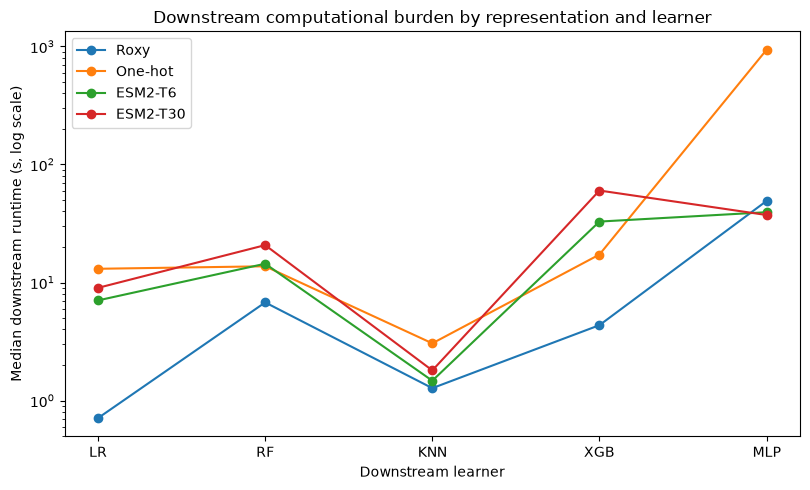

In [9]:
fig, ax = plt.subplots(figsize=(8.2, 5.0))

for rep in REP_ORDER:
    g = (
        supervised_runtime_summary[
            supervised_runtime_summary[
                "representation"
            ].astype(str).eq(rep)
        ]
        .sort_values("algorithm")
    )

    ax.plot(
        [str(x) for x in g["algorithm"]],
        g["median_runtime_s"],
        marker="o",
        label=REP_LABELS[rep],
    )

ax.set_yscale("log")
ax.set_xlabel("Downstream learner")
ax.set_ylabel("Median downstream runtime (s, log scale)")
ax.set_title("Downstream computational burden by representation and learner")
ax.legend()
plt.tight_layout()
plt.show()


# 8. Task and R/S dependence of downstream runtime


In [10]:
runtime_by_task = (
    sup_compute.groupby("task")
    ["downstream_runtime_seconds"]
    .agg(
        n="count",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

runtime_by_R = (
    sup_compute.groupby("R")
    ["downstream_runtime_seconds"]
    .agg(
        n="count",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(R_LEVELS)
    .reset_index()
)

runtime_by_S = (
    sup_compute.groupby("S")
    ["downstream_runtime_seconds"]
    .agg(
        n="count",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(S_LEVELS)
    .reset_index()
)

display(runtime_by_task)
display(runtime_by_R)
display(runtime_by_S)


,task,n,median,q25,q75
0,global_easy,320,16.957141,6.017121,60.377791
1,global_hard,320,6.411089,1.000410,16.861555
2,global_mixed,320,17.510350,5.718965,71.490074
3,multiclass_clean,320,6.564371,0.809291,23.360370
4,subtype_depolymerase,320,10.031392,4.094919,32.551928
5,subtype_endolysin,320,17.493785,6.361001,58.552398
6,subtype_val,320,7.464860,3.317123,20.602952


,R,n,median,q25,q75
0,90,560,16.402834,5.701056,56.796286
1,70,560,13.600197,4.756158,41.795483
2,50,560,10.121117,3.064727,32.228617
3,30,560,8.406313,1.509596,20.264720


,S,n,median,q25,q75
0,90,560,11.830802,4.237355,36.407778
1,70,560,11.733927,4.108546,35.704930
2,50,560,11.715593,3.996631,35.734945
3,30,560,11.822027,4.106158,35.715196


# 9. Paired runtime change across R and S


In [11]:
R_PAIR_KEYS = [
    "task",
    "S",
    "representation",
    "algorithm",
]

wide_R = sup_compute.pivot_table(
    index=R_PAIR_KEYS,
    columns="R",
    values=[
        "downstream_runtime_seconds",
        "mcc",
    ],
    aggfunc="first",
)

r_runtime_contrasts = pd.DataFrame({
    **{
        key: wide_R.index.get_level_values(key)
        for key in R_PAIR_KEYS
    },
    "runtime_R90": wide_R[
        ("downstream_runtime_seconds", 90)
    ].to_numpy(),
    "runtime_R30": wide_R[
        ("downstream_runtime_seconds", 30)
    ].to_numpy(),
    "mcc_R90": wide_R[
        ("mcc", 90)
    ].to_numpy(),
    "mcc_R30": wide_R[
        ("mcc", 30)
    ].to_numpy(),
})

r_runtime_contrasts["runtime_ratio_R30_over_R90"] = (
    r_runtime_contrasts["runtime_R30"]
    / r_runtime_contrasts["runtime_R90"]
)

r_runtime_contrasts["delta_mcc_R30_minus_R90"] = (
    r_runtime_contrasts["mcc_R30"]
    - r_runtime_contrasts["mcc_R90"]
)

S_PAIR_KEYS = [
    "task",
    "R",
    "representation",
    "algorithm",
]

wide_S = sup_compute.pivot_table(
    index=S_PAIR_KEYS,
    columns="S",
    values=[
        "downstream_runtime_seconds",
        "mcc",
    ],
    aggfunc="first",
)

s_runtime_contrasts = pd.DataFrame({
    **{
        key: wide_S.index.get_level_values(key)
        for key in S_PAIR_KEYS
    },
    "runtime_S90": wide_S[
        ("downstream_runtime_seconds", 90)
    ].to_numpy(),
    "runtime_S30": wide_S[
        ("downstream_runtime_seconds", 30)
    ].to_numpy(),
    "mcc_S90": wide_S[
        ("mcc", 90)
    ].to_numpy(),
    "mcc_S30": wide_S[
        ("mcc", 30)
    ].to_numpy(),
})

s_runtime_contrasts["runtime_ratio_S30_over_S90"] = (
    s_runtime_contrasts["runtime_S30"]
    / s_runtime_contrasts["runtime_S90"]
)

s_runtime_contrasts["delta_mcc_S30_minus_S90"] = (
    s_runtime_contrasts["mcc_S30"]
    - s_runtime_contrasts["mcc_S90"]
)

display(
    r_runtime_contrasts[
        "runtime_ratio_R30_over_R90"
    ].describe()
)

display(
    s_runtime_contrasts[
        "runtime_ratio_S30_over_S90"
    ].describe()
)


count    560.000000
mean       0.467598
std        0.293159
min        0.041908
25%        0.244627
50%        0.417749
75%        0.631129
max        2.958859
Name: runtime_ratio_R30_over_R90, dtype: float64

count    560.000000
mean       1.014807
std        0.258223
min        0.212948
25%        0.912524
50%        0.994692
75%        1.071572
max        3.594082
Name: runtime_ratio_S30_over_S90, dtype: float64

These runtime ratios are descriptive consequences of the executed R/S datasets.

They do not reinterpret the biological R/S effects. In particular, R changes the available evidence population, so a lower R runtime can coexist with a worse native benchmark result because the training universe itself is smaller/restructured.


# 10. Runtime scaling with train size and feature dimension, where available


In [12]:
scaling_rows = []

for predictor in [
    "runtime_n_train",
    "n_features",
]:
    available = sup_compute[
        [
            predictor,
            "downstream_runtime_seconds",
            "representation",
            "algorithm",
        ]
    ].dropna()

    if len(available) == 0:
        continue

    for (rep, alg), g in available.groupby(
        ["representation", "algorithm"]
    ):
        if (
            len(g) < 8
            or g[predictor].nunique() < 2
        ):
            rho = np.nan
        else:
            rho = g[predictor].corr(
                g["downstream_runtime_seconds"],
                method="spearman",
            )

        scaling_rows.append({
            "predictor": predictor,
            "representation": rep,
            "algorithm": alg,
            "n": len(g),
            "spearman_rho": rho,
        })

runtime_scaling = pd.DataFrame(
    scaling_rows
)

if len(runtime_scaling):
    display(runtime_scaling)

    display(
        runtime_scaling.groupby(
            ["predictor", "algorithm"]
        )["spearman_rho"]
        .agg(
            n="count",
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
        )
        .reset_index()
    )
else:
    print(
        "Train-size/feature-dimension runtime scaling cannot be quantified "
        "because those optional runtime fields were not recorded with usable coverage."
    )


,predictor,representation,algorithm,n,spearman_rho
0,runtime_n_train,esm2_t30_150m,KNN,112,0.991137
1,runtime_n_train,esm2_t30_150m,LR,112,0.165040
2,runtime_n_train,esm2_t30_150m,MLP,112,0.847436
3,runtime_n_train,esm2_t30_150m,RF,112,0.933524
4,runtime_n_train,esm2_t30_150m,XGB,112,0.607976
5,runtime_n_train,esm2_t6_8m,KNN,112,0.993175
6,runtime_n_train,esm2_t6_8m,LR,112,0.549820
7,runtime_n_train,esm2_t6_8m,MLP,112,0.847299
8,runtime_n_train,esm2_t6_8m,RF,112,0.940738
9,runtime_n_train,esm2_t6_8m,XGB,112,0.659626


,predictor,algorithm,n,median,q25,q75
0,n_features,KNN,0,NaN,NaN,NaN
1,n_features,LR,0,NaN,NaN,NaN
2,n_features,MLP,0,NaN,NaN,NaN
3,n_features,RF,0,NaN,NaN,NaN
4,n_features,XGB,0,NaN,NaN,NaN
5,runtime_n_train,KNN,4,0.992156,0.989337,0.993746
6,runtime_n_train,LR,4,0.391245,0.215762,0.638086
7,runtime_n_train,MLP,4,0.848015,0.847402,0.864089
8,runtime_n_train,RF,4,0.937131,0.919054,0.945931
9,runtime_n_train,XGB,4,0.455113,0.273420,0.620889


# 11. Peak-memory burden, where available


In [13]:
if sup_compute["peak_rss_mb"].notna().any():
    memory_summary = (
        sup_compute.groupby(
            ["representation", "algorithm"]
        )["peak_rss_mb"]
        .agg(
            n="count",
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
            max="max",
        )
        .reset_index()
    )

    display(memory_summary)
else:
    memory_summary = pd.DataFrame()

    print(
        "Peak-RSS metadata are not available with usable coverage. "
        "RQ18 will not infer memory burden from representation size."
    )

if sup_compute["peak_delta_mb"].notna().any():
    memory_delta_summary = (
        sup_compute.groupby(
            ["representation", "algorithm"]
        )["peak_delta_mb"]
        .agg(
            n="count",
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
            max="max",
        )
        .reset_index()
    )

    display(memory_delta_summary)
else:
    memory_delta_summary = pd.DataFrame()


,representation,algorithm,n,median,q25,q75,max
0,esm2_t30_150m,KNN,112,5046.599609,4270.984375,5174.533203,5320.988281
1,esm2_t30_150m,LR,112,5041.207031,4270.984375,5150.906250,5320.988281
2,esm2_t30_150m,MLP,112,5046.599609,4270.984375,5174.533203,5320.988281
3,esm2_t30_150m,RF,112,5041.207031,4270.984375,5150.906250,5320.988281
4,esm2_t30_150m,XGB,112,5046.599609,4270.984375,5174.533203,5320.988281
5,esm2_t6_8m,KNN,112,4437.285156,2334.355469,4603.789062,4615.832031
6,esm2_t6_8m,LR,112,4415.179688,2334.355469,4603.789062,4615.832031
7,esm2_t6_8m,MLP,112,4437.285156,2334.355469,4603.789062,4615.832031
8,esm2_t6_8m,RF,112,4415.179688,2334.355469,4603.789062,4615.832031
9,esm2_t6_8m,XGB,112,4437.285156,2334.355469,4603.789062,4615.832031


,representation,algorithm,n,median,q25,q75,max
0,esm2_t30_150m,KNN,112,0.0,0.0,0.0,830.253906
1,esm2_t30_150m,LR,112,0.0,0.0,0.0,0.000000
2,esm2_t30_150m,MLP,112,0.0,0.0,0.0,0.000000
3,esm2_t30_150m,RF,112,0.0,0.0,0.0,0.000000
4,esm2_t30_150m,XGB,112,0.0,0.0,0.0,0.000000
5,esm2_t6_8m,KNN,112,0.0,0.0,0.0,1287.648438
6,esm2_t6_8m,LR,112,0.0,0.0,0.0,0.000000
7,esm2_t6_8m,MLP,112,0.0,0.0,0.0,0.000000
8,esm2_t6_8m,RF,112,0.0,0.0,0.0,0.000000
9,esm2_t6_8m,XGB,112,0.0,0.0,0.0,0.000000


# 12. Cell-wise performance/runtime Pareto frontier


In [14]:
pareto_frames = []

for keys, g in sup_compute.groupby(
    ["task", "R", "S"],
    sort=False,
):
    task, r, s = keys

    x = g.copy()

    valid = (
        x["mcc"].notna()
        & x["downstream_runtime_seconds"].notna()
        & (x["downstream_runtime_seconds"] > 0)
    )

    x["pareto_efficient"] = False

    if valid.any():
        x.loc[
            valid,
            "pareto_efficient",
        ] = pareto_mask(
            x.loc[valid, "mcc"],
            x.loc[
                valid,
                "downstream_runtime_seconds",
            ],
        )

    best_mcc = x.loc[valid, "mcc"].max()

    x["cell_best_mcc"] = best_mcc

    x["mcc_gap_to_cell_best"] = (
        best_mcc - x["mcc"]
    )

    x["near_best_0p02"] = (
        valid
        & (
            x["mcc_gap_to_cell_best"]
            <= NEAR_BEST_MCC_TOL
        )
    )

    pareto_frames.append(x)

sup_efficiency = pd.concat(
    pareto_frames,
    ignore_index=True,
)

pareto_summary = (
    sup_efficiency.groupby(
        ["representation", "algorithm"]
    )
    .agg(
        n_cells=("pareto_efficient", "size"),
        pareto_count=("pareto_efficient", "sum"),
        pareto_rate=("pareto_efficient", "mean"),
        near_best_count=("near_best_0p02", "sum"),
        near_best_rate=("near_best_0p02", "mean"),
        median_mcc=("mcc", "median"),
        median_gap_to_best=(
            "mcc_gap_to_cell_best",
            "median",
        ),
        median_runtime_s=(
            "downstream_runtime_seconds",
            "median",
        ),
    )
    .reset_index()
)

display(
    pareto_summary.sort_values(
        [
            "pareto_rate",
            "near_best_rate",
            "median_runtime_s",
        ],
        ascending=[False, False, True],
    )
)


,representation,algorithm,n_cells,pareto_count,pareto_rate,near_best_count,near_best_rate,median_mcc,median_gap_to_best,median_runtime_s
0,esm2_t30_150m,KNN,112,97,0.866071,88,0.785714,0.914002,0.002436,1.799893
5,esm2_t6_8m,KNN,112,97,0.866071,20,0.178571,0.846732,0.080300,1.471981
15,roxy_48,KNN,112,89,0.794643,0,0.000000,0.713270,0.236159,1.273187
16,roxy_48,LR,112,55,0.491071,0,0.000000,0.490366,0.440130,0.710221
2,esm2_t30_150m,MLP,112,36,0.321429,101,0.901786,0.917424,0.003717,37.310196
1,esm2_t30_150m,LR,112,27,0.241071,29,0.258929,0.881722,0.038247,9.010938
4,esm2_t30_150m,XGB,112,13,0.116071,85,0.758929,0.911199,0.009478,60.170512
3,esm2_t30_150m,RF,112,9,0.080357,21,0.187500,0.879959,0.044150,20.737186
19,roxy_48,XGB,112,6,0.053571,0,0.000000,0.735905,0.210377,4.350882
7,esm2_t6_8m,MLP,112,5,0.044643,20,0.178571,0.859685,0.068886,39.415624


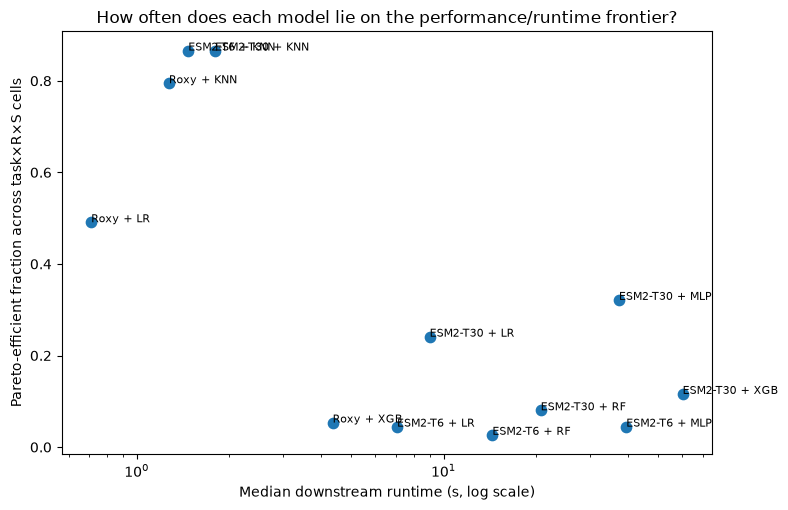

In [15]:
top_pareto = (
    pareto_summary.sort_values(
        "pareto_rate",
        ascending=False,
    )
    .head(12)
    .copy()
)

top_pareto["model"] = (
    top_pareto["representation"].map(REP_LABELS)
    + " + "
    + top_pareto["algorithm"].astype(str)
)

fig, ax = plt.subplots(figsize=(8.0, 5.2))

ax.scatter(
    top_pareto["median_runtime_s"],
    top_pareto["pareto_rate"],
    s=55,
)

for row in top_pareto.itertuples(index=False):
    ax.annotate(
        row.model,
        (
            row.median_runtime_s,
            row.pareto_rate,
        ),
        fontsize=8,
    )

ax.set_xscale("log")
ax.set_xlabel("Median downstream runtime (s, log scale)")
ax.set_ylabel("Pareto-efficient fraction across task×R×S cells")
ax.set_title("How often does each model lie on the performance/runtime frontier?")
plt.tight_layout()
plt.show()


A high Pareto rate means that a model is frequently non-dominated within the exact same biological task/R/S evaluation cell.

It does **not** mean that the model has the highest MCC. A lower-performing model can remain Pareto-efficient if its downstream computational burden is sufficiently lower.


# 13. Near-best performance at ≤0.02 MCC from the cell best


In [16]:
near_best_summary = (
    sup_efficiency.groupby(
        ["representation", "algorithm"]
    )
    .agg(
        n=("near_best_0p02", "size"),
        near_best_rate=(
            "near_best_0p02",
            "mean",
        ),
        median_gap_to_best=(
            "mcc_gap_to_cell_best",
            "median",
        ),
        median_runtime_s=(
            "downstream_runtime_seconds",
            "median",
        ),
    )
    .reset_index()
)

display(
    near_best_summary.sort_values(
        [
            "near_best_rate",
            "median_runtime_s",
        ],
        ascending=[False, True],
    )
)

near_best_by_task = (
    sup_efficiency.groupby(
        [
            "task",
            "representation",
            "algorithm",
        ]
    )
    .agg(
        near_best_rate=(
            "near_best_0p02",
            "mean",
        ),
        median_gap_to_best=(
            "mcc_gap_to_cell_best",
            "median",
        ),
        median_runtime_s=(
            "downstream_runtime_seconds",
            "median",
        ),
    )
    .reset_index()
)

display(
    near_best_by_task.sort_values(
        [
            "task",
            "near_best_rate",
            "median_runtime_s",
        ],
        ascending=[True, False, True],
    )
)


,representation,algorithm,n,near_best_rate,median_gap_to_best,median_runtime_s
2,esm2_t30_150m,MLP,112,0.901786,0.003717,37.310196
0,esm2_t30_150m,KNN,112,0.785714,0.002436,1.799893
4,esm2_t30_150m,XGB,112,0.758929,0.009478,60.170512
1,esm2_t30_150m,LR,112,0.258929,0.038247,9.010938
3,esm2_t30_150m,RF,112,0.187500,0.044150,20.737186
5,esm2_t6_8m,KNN,112,0.178571,0.080300,1.471981
7,esm2_t6_8m,MLP,112,0.178571,0.068886,39.415624
9,esm2_t6_8m,XGB,112,0.169643,0.078349,32.832234
6,esm2_t6_8m,LR,112,0.133929,0.189472,7.054229
8,esm2_t6_8m,RF,112,0.080357,0.150006,14.429821


,task,representation,algorithm,near_best_rate,median_gap_to_best,median_runtime_s
0,global_easy,esm2_t30_150m,KNN,1.0000,0.000000,2.857057
2,global_easy,esm2_t30_150m,MLP,0.8750,0.003133,78.744082
4,global_easy,esm2_t30_150m,XGB,0.8750,0.011294,94.989578
15,global_easy,roxy_48,KNN,0.0000,0.281030,1.843818
5,global_easy,esm2_t6_8m,KNN,0.0000,0.118306,2.380511
16,global_easy,roxy_48,LR,0.0000,0.454392,3.189922
10,global_easy,onehot_1024,KNN,0.0000,0.430239,5.328307
19,global_easy,roxy_48,XGB,0.0000,0.239903,5.464495
1,global_easy,esm2_t30_150m,LR,0.0000,0.038935,11.152947
18,global_easy,roxy_48,RF,0.0000,0.301727,11.894483


# 14. Direct test: T30 + simple learner versus T30 + complex learners


In [17]:
t30 = sup_compute[
    sup_compute["representation"].eq(
        "esm2_t30_150m"
    )
].copy()

T30_KEYS = [
    "task",
    "R",
    "S",
]

t30_mcc_wide = t30.pivot_table(
    index=T30_KEYS,
    columns="algorithm",
    values="mcc",
    aggfunc="first",
)

t30_runtime_wide = t30.pivot_table(
    index=T30_KEYS,
    columns="algorithm",
    values="downstream_runtime_seconds",
    aggfunc="first",
)

simple_complex_rows = []

for simple_alg in ["LR"]:
    for complex_alg in [
        a for a in ["MLP", "XGB", "RF", "KNN"]
        if a in t30_mcc_wide.columns
    ]:
        common_idx = (
            t30_mcc_wide[
                [simple_alg, complex_alg]
            ].dropna().index
            .intersection(
                t30_runtime_wide[
                    [simple_alg, complex_alg]
                ].dropna().index
            )
        )

        for idx in common_idx:
            task, r, s = idx

            m_simple = float(
                t30_mcc_wide.loc[
                    idx,
                    simple_alg,
                ]
            )
            m_complex = float(
                t30_mcc_wide.loc[
                    idx,
                    complex_alg,
                ]
            )

            rt_simple = float(
                t30_runtime_wide.loc[
                    idx,
                    simple_alg,
                ]
            )
            rt_complex = float(
                t30_runtime_wide.loc[
                    idx,
                    complex_alg,
                ]
            )

            simple_complex_rows.append({
                "task": task,
                "R": r,
                "S": s,
                "representation": "esm2_t30_150m",
                "simple_algorithm": simple_alg,
                "comparison_algorithm": complex_alg,
                "delta_mcc_simple_minus_comparison": (
                    m_simple - m_complex
                ),
                "abs_mcc_difference": abs(
                    m_simple - m_complex
                ),
                "runtime_simple_s": rt_simple,
                "runtime_comparison_s": rt_complex,
                "runtime_ratio_simple_over_comparison": (
                    rt_simple / rt_complex
                    if rt_complex > 0
                    else np.nan
                ),
                "simple_within_0p02_mcc": (
                    m_simple >= m_complex - 0.02
                ),
                "simple_faster": (
                    rt_simple < rt_complex
                ),
                "simple_near_and_faster": (
                    (m_simple >= m_complex - 0.02)
                    and (rt_simple < rt_complex)
                ),
            })

simple_vs_complex = pd.DataFrame(
    simple_complex_rows
)

simple_vs_complex_summary = (
    simple_vs_complex.groupby(
        [
            "simple_algorithm",
            "comparison_algorithm",
        ]
    )
    .agg(
        n=("task", "size"),
        median_delta_mcc=(
            "delta_mcc_simple_minus_comparison",
            "median",
        ),
        median_abs_mcc_difference=(
            "abs_mcc_difference",
            "median",
        ),
        fraction_within_0p02=(
            "simple_within_0p02_mcc",
            "mean",
        ),
        median_runtime_ratio=(
            "runtime_ratio_simple_over_comparison",
            "median",
        ),
        fraction_simple_faster=(
            "simple_faster",
            "mean",
        ),
        fraction_near_and_faster=(
            "simple_near_and_faster",
            "mean",
        ),
    )
    .reset_index()
)

display(simple_vs_complex_summary)

display(
    simple_vs_complex.groupby(
        [
            "task",
            "comparison_algorithm",
        ]
    )
    .agg(
        median_delta_mcc=(
            "delta_mcc_simple_minus_comparison",
            "median",
        ),
        fraction_within_0p02=(
            "simple_within_0p02_mcc",
            "mean",
        ),
        median_runtime_ratio=(
            "runtime_ratio_simple_over_comparison",
            "median",
        ),
        fraction_near_and_faster=(
            "simple_near_and_faster",
            "mean",
        ),
    )
    .reset_index()
)


,simple_algorithm,comparison_algorithm,n,median_delta_mcc,median_abs_mcc_difference,fraction_within_0p02,median_runtime_ratio,fraction_simple_faster,fraction_near_and_faster
0,LR,KNN,112,-0.028763,0.033655,0.375000,4.321357,0.107143,0.062500
1,LR,MLP,112,-0.034526,0.035260,0.321429,0.129363,0.955357,0.294643
2,LR,RF,112,-0.000790,0.012619,0.919643,0.277547,0.866071,0.794643
3,LR,XGB,112,-0.022620,0.029265,0.464286,0.120107,1.000000,0.464286


,task,comparison_algorithm,median_delta_mcc,fraction_within_0p02,median_runtime_ratio,fraction_near_and_faster
0,global_easy,KNN,-0.032736,0.0000,4.035403,0.0000
1,global_easy,MLP,-0.035116,0.0000,0.144463,0.0000
2,global_easy,RF,0.005370,1.0000,0.205371,1.0000
3,global_easy,XGB,-0.027565,0.1250,0.123422,0.1250
4,global_hard,KNN,0.000144,0.9375,7.492296,0.0000
5,global_hard,MLP,-0.002420,1.0000,0.252689,1.0000
6,global_hard,RF,-0.007290,0.8750,0.611896,0.7500
7,global_hard,XGB,-0.006232,1.0000,0.156736,1.0000
8,global_mixed,KNN,-0.047309,0.0000,4.341941,0.0000
9,global_mixed,MLP,-0.046776,0.0000,0.106721,0.0000


This is the direct operational test of the roadmap statement:

> can a simple learner operating on a strong representation approach the performance of more complex models?

The result is reported as a matched distribution, not as a universal statement about Logistic Regression.


# 15. Downstream cost of representation scaling: T30 versus T6/Roxy


In [18]:
REP_PAIR_KEYS = [
    "task",
    "R",
    "S",
    "algorithm",
]

rep_mcc_wide = sup_compute.pivot_table(
    index=REP_PAIR_KEYS,
    columns="representation",
    values="mcc",
    aggfunc="first",
)

rep_runtime_wide = sup_compute.pivot_table(
    index=REP_PAIR_KEYS,
    columns="representation",
    values="downstream_runtime_seconds",
    aggfunc="first",
)

rep_runtime_rows = []

for rep_a, rep_b, label in [
    (
        "esm2_t6_8m",
        "esm2_t30_150m",
        "T30_minus_T6",
    ),
    (
        "roxy_48",
        "esm2_t30_150m",
        "T30_minus_Roxy",
    ),
]:
    common_idx = (
        rep_mcc_wide[
            [rep_a, rep_b]
        ].dropna().index
        .intersection(
            rep_runtime_wide[
                [rep_a, rep_b]
            ].dropna().index
        )
    )

    for idx in common_idx:
        task, r, s, alg = idx

        m_a = float(
            rep_mcc_wide.loc[
                idx,
                rep_a,
            ]
        )
        m_b = float(
            rep_mcc_wide.loc[
                idx,
                rep_b,
            ]
        )

        rt_a = float(
            rep_runtime_wide.loc[
                idx,
                rep_a,
            ]
        )
        rt_b = float(
            rep_runtime_wide.loc[
                idx,
                rep_b,
            ]
        )

        rep_runtime_rows.append({
            "contrast": label,
            "task": task,
            "R": r,
            "S": s,
            "algorithm": alg,
            "representation_A": rep_a,
            "representation_B": rep_b,
            "delta_mcc_B_minus_A": m_b - m_a,
            "runtime_A_s": rt_a,
            "runtime_B_s": rt_b,
            "runtime_ratio_B_over_A": (
                rt_b / rt_a
                if rt_a > 0
                else np.nan
            ),
        })

representation_runtime_contrasts = pd.DataFrame(
    rep_runtime_rows
)

representation_runtime_summary = (
    representation_runtime_contrasts.groupby(
        ["contrast", "algorithm"]
    )
    .agg(
        n=("task", "size"),
        median_delta_mcc=(
            "delta_mcc_B_minus_A",
            "median",
        ),
        median_runtime_ratio=(
            "runtime_ratio_B_over_A",
            "median",
        ),
        q25_runtime_ratio=(
            "runtime_ratio_B_over_A",
            lambda x: x.quantile(0.25),
        ),
        q75_runtime_ratio=(
            "runtime_ratio_B_over_A",
            lambda x: x.quantile(0.75),
        ),
        fraction_B_faster=(
            "runtime_ratio_B_over_A",
            lambda x: (x < 1).mean(),
        ),
    )
    .reset_index()
)

display(representation_runtime_summary)


,contrast,algorithm,n,median_delta_mcc,median_runtime_ratio,q25_runtime_ratio,q75_runtime_ratio,fraction_B_faster
0,T30_minus_Roxy,KNN,112,0.236159,1.445117,1.329109,1.575889,0.044643
1,T30_minus_Roxy,LR,112,0.394014,7.263704,2.433301,20.206568,0.116071
2,T30_minus_Roxy,MLP,112,0.227417,0.856854,0.665073,1.084926,0.669643
3,T30_minus_Roxy,RF,112,0.202275,3.038270,1.779107,4.002860,0.000000
4,T30_minus_Roxy,XGB,112,0.187208,15.080835,10.597428,17.768894,0.000000
5,T30_minus_T6,KNN,112,0.073051,1.186358,1.112502,1.250849,0.098214
6,T30_minus_T6,LR,112,0.150935,0.936679,0.740430,1.241849,0.562500
7,T30_minus_T6,MLP,112,0.065530,1.143263,0.908870,1.397827,0.312500
8,T30_minus_T6,RF,112,0.097973,1.403183,1.248660,1.595379,0.008929
9,T30_minus_T6,XGB,112,0.065805,1.953697,1.566534,2.296494,0.026786


This section concerns **downstream learner runtime only**.

A T30 model can take more or less downstream time than the same learner on T6 depending on dimensionality, preprocessing, sparsity, and implementation. The much larger *embedding extraction* burden of T30, if present, is handled separately below.


# 16. Prediction-time burden, if separately logged


In [19]:
if sup_compute["prediction_seconds"].notna().any():
    prediction_time_summary = (
        sup_compute.groupby(
            ["representation", "algorithm"]
        )["prediction_seconds"]
        .agg(
            n="count",
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
            max="max",
        )
        .reset_index()
    )

    display(prediction_time_summary)
else:
    prediction_time_summary = pd.DataFrame()

    print(
        "No independently logged test-prediction timing is available. "
        "Prediction cost will not be reconstructed from total runtime."
    )


,representation,algorithm,n,median,q25,q75,max
0,esm2_t30_150m,KNN,112,0.506336,0.226934,1.161195,3.933175
1,esm2_t30_150m,LR,112,0.092792,0.073569,0.107174,0.177467
2,esm2_t30_150m,MLP,112,0.060425,0.044129,0.088154,0.230986
3,esm2_t30_150m,RF,112,0.102070,0.085562,0.130128,0.282757
4,esm2_t30_150m,XGB,112,0.035962,0.029153,0.046196,0.116089
5,esm2_t6_8m,KNN,112,0.422212,0.195014,0.950727,2.698539
6,esm2_t6_8m,LR,112,0.087129,0.061859,0.105310,0.135546
7,esm2_t6_8m,MLP,112,0.055736,0.045078,0.077943,0.117772
8,esm2_t6_8m,RF,112,0.108200,0.083708,0.130858,0.251810
9,esm2_t6_8m,XGB,112,0.034086,0.028210,0.046693,0.083201


# 17. Identify the empirically highest-cost supervised combinations


In [20]:
high_cost_supervised = (
    sup_compute[
        [
            "task",
            "R",
            "S",
            "representation",
            "algorithm",
            "mcc",
            "downstream_runtime_seconds",
            "peak_rss_mb",
            "peak_delta_mb",
        ]
    ]
    .dropna(
        subset=["downstream_runtime_seconds"]
    )
    .sort_values(
        "downstream_runtime_seconds",
        ascending=False,
    )
    .head(30)
)

display(high_cost_supervised)

high_cost_family_summary = (
    sup_compute.groupby(
        ["representation", "algorithm"]
    )["downstream_runtime_seconds"]
    .agg(
        median="median",
        q90=lambda x: x.quantile(0.90),
        q95=lambda x: x.quantile(0.95),
        max="max",
    )
    .reset_index()
    .sort_values(
        "q95",
        ascending=False,
    )
)

display(high_cost_family_summary)


,task,R,S,representation,algorithm,mcc,downstream_runtime_seconds,peak_rss_mb,peak_delta_mb
1009,subtype_endolysin,90,50,onehot_1024,MLP,0.549181,3549.101140,4529.285156,0.0
989,subtype_endolysin,90,70,onehot_1024,MLP,0.536787,3302.395822,4529.285156,0.0
1029,subtype_endolysin,90,30,onehot_1024,MLP,0.452898,3268.016416,4529.285156,0.0
969,subtype_endolysin,90,90,onehot_1024,MLP,0.614371,2896.175745,3814.792969,0.0
709,global_mixed,90,30,onehot_1024,MLP,0.516711,2893.800953,4682.812500,0.0
689,global_mixed,90,50,onehot_1024,MLP,0.537189,2862.642103,4682.812500,0.0
649,global_mixed,90,90,onehot_1024,MLP,0.636875,2854.559685,3851.562500,0.0
729,global_mixed,70,90,onehot_1024,MLP,0.541936,2846.032077,4682.812500,0.0
669,global_mixed,90,70,onehot_1024,MLP,0.620206,2715.960661,4612.832031,0.0
749,global_mixed,70,70,onehot_1024,MLP,0.533938,2640.005121,4682.812500,0.0


,representation,algorithm,median,q90,q95,max
12,onehot_1024,MLP,937.775445,2299.565669,2858.196773,3549.101140
17,roxy_48,MLP,49.107800,135.661057,151.337409,225.252163
2,esm2_t30_150m,MLP,37.310196,124.943996,142.135260,496.244941
7,esm2_t6_8m,MLP,39.415624,110.804539,138.284739,187.895716
4,esm2_t30_150m,XGB,60.170512,112.328674,134.217387,247.145714
3,esm2_t30_150m,RF,20.737186,78.367785,100.319767,126.451907
13,onehot_1024,RF,13.723900,67.980644,76.422291,82.533118
9,esm2_t6_8m,XGB,32.832234,64.306267,72.596629,100.287113
8,esm2_t6_8m,RF,14.429821,53.290268,59.602960,66.542556
14,onehot_1024,XGB,17.258096,38.241588,44.815345,69.928142


# 18. Build PU compute table with runtime fallback hierarchy


In [21]:
RQ12_NATIVE_PATH = (
    PU_CACHE
    / "rq12_pu_native_score_diagnostics.tsv"
)

if not RQ12_NATIVE_PATH.is_file():
    raise FileNotFoundError(
        "RQ18 expects the corrected RQ12 native PU diagnostics cache: "
        f"{RQ12_NATIVE_PATH}"
    )

pu_perf = pd.read_csv(
    RQ12_NATIVE_PATH,
    sep="\t",
    low_memory=False,
)

PRIMARY_PU = "fraction_P_above_U95"

required_perf = {
    "task",
    "R",
    "S",
    "representation",
    "method",
    "algorithm",
    PRIMARY_PU,
}
missing = required_perf - set(pu_perf.columns)
if missing:
    raise KeyError(
        f"RQ12 PU cache missing columns: {sorted(missing)}"
    )


def read_json_if_exists(path):
    if not path.is_file():
        return {}

    try:
        return json.loads(
            path.read_text()
        )
    except Exception:
        return {}

def _runtime_from_flat(flat, source_prefix):
    if not flat:
        return np.nan, None, {}

    canonical = canonical_runtime_record(flat)

    runtime = canonical[
        "downstream_runtime_seconds"
    ]

    source = (
        f"{source_prefix}::{canonical['runtime_source_key']}"
        if pd.notna(runtime)
        and canonical["runtime_source_key"] is not None
        else None
    )

    return runtime, source, canonical

def _runtime_from_tsv(path):
    """
    Search a small diagnostic/runtime TSV for an explicitly named total
    runtime field. We do not sum fit/prediction components.
    """
    try:
        df = pd.read_csv(
            path,
            sep="\t",
            low_memory=False,
        )
    except Exception:
        return np.nan, None

    if len(df) == 0:
        return np.nan, None

    # Exact frozen/common total-runtime names first.
    exact = [
        "validation_and_final_wall_seconds",
        "runtime_seconds",
        "total_runtime_seconds",
        "wall_clock_seconds",
        "total_wall_clock_seconds",
        "elapsed_seconds",
        "total_seconds",
        "experiment_runtime_seconds",
    ]

    for col in exact:
        if col not in df.columns:
            continue

        vals = pd.to_numeric(
            df[col],
            errors="coerce",
        ).dropna()

        if len(vals):
            return (
                float(vals.iloc[0]),
                f"{path.name}::{col}",
            )

    # Conservative generic fallback using the same parser logic as JSON.
    row = df.iloc[0].to_dict()
    runtime, key = choose_generic_total_runtime(
        row
    )

    if pd.notna(runtime):
        return (
            float(runtime),
            f"{path.name}::{key}",
        )

    return np.nan, None

def discover_pu_runtime(exp_dir):
    """
    Discover PU wall time without assuming a single trainer version.

    Search order:
      1) runtime.json
      2) pu_diagnostics.tsv
      3) manifest.json
      4) other direct-child JSON/TSV artifacts whose names contain
         runtime/diagnostic/manifest/timing.

    Returns runtime, source, canonical metadata, discovery audit.
    """
    audit = []
    canonical_best = {}

    preferred = [
        exp_dir / "runtime.json",
        exp_dir / "pu_diagnostics.tsv",
        exp_dir / "manifest.json",
    ]

    extra = []

    if exp_dir.is_dir():
        for p in exp_dir.iterdir():
            if not p.is_file():
                continue

            low = p.name.lower()

            if (
                p.suffix.lower() in {".json", ".tsv"}
                and any(
                    token in low
                    for token in [
                        "runtime",
                        "diagnostic",
                        "manifest",
                        "timing",
                    ]
                )
            ):
                extra.append(p)

    candidates = []

    seen = set()

    for p in preferred + sorted(extra):
        key = str(p)

        if key in seen:
            continue

        seen.add(key)
        candidates.append(p)

    for path in candidates:
        audit.append({
            "artifact": path.name,
            "exists": path.is_file(),
        })

        if not path.is_file():
            continue

        if path.suffix.lower() == ".json":
            obj = read_json_if_exists(path)
            flat = flatten_json(obj) if obj else {}

            runtime, source, canonical = _runtime_from_flat(
                flat,
                path.name,
            )

            if canonical and not canonical_best:
                canonical_best = canonical

            if pd.notna(runtime):
                return (
                    float(runtime),
                    source,
                    canonical,
                    audit,
                )

        elif path.suffix.lower() == ".tsv":
            runtime, source = _runtime_from_tsv(path)

            if pd.notna(runtime):
                return (
                    float(runtime),
                    source,
                    canonical_best,
                    audit,
                )

    return (
        np.nan,
        None,
        canonical_best,
        audit,
    )

pu_runtime_rows = []
pu_schema_rows = []
pu_discovery_rows = []

for rec in pu_registry.to_dict("records"):
    exp_dir = Path(rec["path"])

    runtime, runtime_source, canonical, discovery_audit = (
        discover_pu_runtime(exp_dir)
    )

    # Read manifest separately for optional counts/sparsity, even if it
    # does not contain a usable wall time.
    manifest = read_json_if_exists(
        exp_dir / "manifest.json"
    )

    manifest_flat = (
        flatten_json(manifest)
        if manifest
        else {}
    )

    manifest_canonical = canonical_runtime_record(
        manifest_flat
    )

    n_train = canonical.get(
        "runtime_n_train",
        np.nan,
    )

    if pd.isna(n_train):
        n_train = manifest_canonical[
            "runtime_n_train"
        ]

    n_test = canonical.get(
        "runtime_n_test",
        np.nan,
    )

    if pd.isna(n_test):
        n_test = manifest_canonical[
            "runtime_n_test"
        ]

    sparse = canonical.get(
        "representation_sparse",
        np.nan,
    )

    if pd.isna(sparse):
        sparse = manifest_canonical[
            "representation_sparse"
        ]

    pu_runtime_rows.append({
        "experiment_id": rec["experiment_id"],
        "downstream_runtime_seconds": runtime,
        "runtime_source": runtime_source,
        "final_fit_seconds": canonical.get(
            "final_fit_seconds",
            np.nan,
        ),
        "prediction_seconds": canonical.get(
            "prediction_seconds",
            np.nan,
        ),
        "peak_rss_mb": canonical.get(
            "peak_rss_mb",
            np.nan,
        ),
        "peak_delta_mb": canonical.get(
            "peak_delta_mb",
            np.nan,
        ),
        "runtime_n_train": n_train,
        "runtime_n_test": n_test,
        "n_features": canonical.get(
            "n_features",
            np.nan,
        ),
        "representation_sparse": sparse,
        "runtime_json_exists": (
            exp_dir / "runtime.json"
        ).is_file(),
        "pu_diagnostics_exists": (
            exp_dir / "pu_diagnostics.tsv"
        ).is_file(),
    })

    for item in discovery_audit:
        pu_discovery_rows.append({
            "experiment_id": rec["experiment_id"],
            **item,
        })

    # Schema audit for every discovered direct runtime-like JSON.
    if exp_dir.is_dir():
        for path in exp_dir.iterdir():
            if (
                path.is_file()
                and path.suffix.lower() == ".json"
                and any(
                    token in path.name.lower()
                    for token in [
                        "runtime",
                        "diagnostic",
                        "manifest",
                        "timing",
                    ]
                )
            ):
                obj = read_json_if_exists(path)
                flat = flatten_json(obj) if obj else {}

                for key in flat:
                    pu_schema_rows.append({
                        "experiment_id": rec["experiment_id"],
                        "artifact": path.name,
                        "runtime_key": key,
                    })

pu_runtime = pd.DataFrame(
    pu_runtime_rows
)

pu_runtime_schema = pd.DataFrame(
    pu_schema_rows
)

pu_runtime_discovery = pd.DataFrame(
    pu_discovery_rows
)

pu_compute = (
    pu_registry.merge(
        pu_runtime,
        on="experiment_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        pu_perf[
            [
                "task",
                "R",
                "S",
                "representation",
                "method",
                "algorithm",
                PRIMARY_PU,
            ]
        ],
        on=[
            "task",
            "R",
            "S",
            "representation",
            "method",
            "algorithm",
        ],
        how="left",
        validate="one_to_one",
    )
)

pu_runtime_coverage = (
    pu_compute[
        "downstream_runtime_seconds"
    ]
    .notna()
    .mean()
)

PU_RUNTIME_AVAILABLE = (
    pu_runtime_coverage > 0
)

print(
    "PU downstream-runtime coverage:",
    f"{pu_runtime_coverage:.1%}",
)

display(
    pu_compute["runtime_source"]
    .fillna("<missing>")
    .value_counts()
    .to_frame("n")
)

if len(pu_runtime_schema):
    display(
        pu_runtime_schema.groupby(
            ["artifact", "runtime_key"]
        )
        .size()
        .sort_values(ascending=False)
        .head(100)
        .to_frame("n_experiments")
    )

if len(pu_runtime_discovery):
    display(
        pu_runtime_discovery.groupby(
            ["artifact", "exists"]
        )
        .size()
        .to_frame("n_experiments")
        .reset_index()
        .sort_values(
            ["exists", "n_experiments"],
            ascending=[False, False],
        )
    )

if not PU_RUNTIME_AVAILABLE:
    print(
        "PU runtime is NOT ESTIMABLE from the retained Stage12 PU artifacts. "
        "The PU performance results remain valid, but RQ18 will skip "
        "PU compute-overhead and broad-vs-conservative runtime claims. "
        "This is a missing instrumentation limitation, not a benchmark failure."
    )



PU downstream-runtime coverage: 0.0%


,n
runtime_source,
<missing>,768


n_experiments
artifact      runtime_key                            
manifest.json R                                   768
              S                                   768
              algorithm                           768
              base_config                         768
              status                              768
              inner_split_sha256                  768
              inner_split_path                    768
              experiment_id                       768
              outer_universe_sha256               768
              representation                      768
              outer_universe_path                 768
              method                              768
              representation_dimension            768
              representation_family               768
              software.numpy                      768
              software.pandas                     768
              seed                                768
              representation_sparse               768
              representation_sha256               768
              representation_path                 768
              task                                768
              software.scipy                      768
              software.xgboost                    768
              stage                               768
              software.python                     768
              software.scikit_learn               768
              bag_score_aggregation               256
              clipping_fraction                   256
              interpretation                      256
              n_bags                              256
              c                                   256
              group_aware_crossfit                256
              crossfit_folds                      256
              score_correction                    256
              u_p_ratio                           256
              u_sampling                          256

,artifact,exists,n_experiments
1,manifest.json,True,768
2,pu_diagnostics.tsv,True,768
0,bagging_diagnostics.tsv,True,256
3,runtime.json,False,768


PU runtime is NOT ESTIMABLE from the retained Stage12 PU artifacts. The PU performance results remain valid, but RQ18 will skip PU compute-overhead and broad-vs-conservative runtime claims. This is a missing instrumentation limitation, not a benchmark failure.


# 19. PU downstream runtime by method, representation, and learner


In [22]:

if PU_RUNTIME_AVAILABLE:
    pu_runtime_summary = (
        pu_compute.groupby(
            [
                "method",
                "representation",
                "algorithm",
            ]
        )
        .agg(
            n=("downstream_runtime_seconds", "count"),
            median_runtime_s=(
                "downstream_runtime_seconds",
                "median",
            ),
            q25_runtime_s=(
                "downstream_runtime_seconds",
                lambda x: x.quantile(0.25),
            ),
            q75_runtime_s=(
                "downstream_runtime_seconds",
                lambda x: x.quantile(0.75),
            ),
            median_U95=(
                PRIMARY_PU,
                "median",
            ),
            median_n_train=(
                "runtime_n_train",
                "median",
            ),
        )
        .reset_index()
    )

    display(
        pu_runtime_summary.sort_values(
            [
                "method",
                "representation",
                "algorithm",
            ]
        )
    )
else:
    pu_runtime_summary = pd.DataFrame(
        columns=[
            "method",
            "representation",
            "algorithm",
            "n",
            "median_runtime_s",
            "q25_runtime_s",
            "q75_runtime_s",
            "median_U95",
            "median_n_train",
        ]
    )

    print(
        "Skipped: PU downstream-runtime summary is not estimable "
        "because no PU wall-time instrumentation was retained."
    )


Skipped: PU downstream-runtime summary is not estimable because no PU wall-time instrumentation was retained.


# 20. Matched PU-method overhead versus naive recovery gain


In [23]:

PU_MATCH_KEYS = [
    "task",
    "R",
    "S",
    "representation",
    "algorithm",
]

pu_method_overhead_columns = [
    "task",
    "R",
    "S",
    "representation",
    "algorithm",
    "method",
    "runtime_naive_s",
    "runtime_method_s",
    "runtime_ratio_method_over_naive",
    "delta_U95_method_minus_naive",
]

if PU_RUNTIME_AVAILABLE:
    pu_runtime_wide = pu_compute.pivot_table(
        index=PU_MATCH_KEYS,
        columns="method",
        values="downstream_runtime_seconds",
        aggfunc="first",
    )

    pu_metric_wide = pu_compute.pivot_table(
        index=PU_MATCH_KEYS,
        columns="method",
        values=PRIMARY_PU,
        aggfunc="first",
    )

    pu_method_overhead_rows = []

    required_methods = {
        "naive",
        "baggingpu",
        "elkan_noto",
    }

    if (
        required_methods
        <= set(pu_runtime_wide.columns)
        and required_methods
        <= set(pu_metric_wide.columns)
    ):
        for method in [
            "baggingpu",
            "elkan_noto",
        ]:
            common_idx = (
                pu_runtime_wide[
                    ["naive", method]
                ]
                .dropna()
                .index
                .intersection(
                    pu_metric_wide[
                        ["naive", method]
                    ]
                    .dropna()
                    .index
                )
            )

            for idx in common_idx:
                task, r, s, rep, alg = idx

                rt_naive = float(
                    pu_runtime_wide.loc[
                        idx,
                        "naive",
                    ]
                )
                rt_method = float(
                    pu_runtime_wide.loc[
                        idx,
                        method,
                    ]
                )

                m_naive = float(
                    pu_metric_wide.loc[
                        idx,
                        "naive",
                    ]
                )
                m_method = float(
                    pu_metric_wide.loc[
                        idx,
                        method,
                    ]
                )

                pu_method_overhead_rows.append({
                    "task": task,
                    "R": r,
                    "S": s,
                    "representation": rep,
                    "algorithm": alg,
                    "method": method,
                    "runtime_naive_s": rt_naive,
                    "runtime_method_s": rt_method,
                    "runtime_ratio_method_over_naive": (
                        rt_method / rt_naive
                        if rt_naive > 0
                        else np.nan
                    ),
                    "delta_U95_method_minus_naive": (
                        m_method - m_naive
                    ),
                })

    pu_method_overhead = pd.DataFrame(
        pu_method_overhead_rows,
        columns=pu_method_overhead_columns,
    )
else:
    pu_method_overhead = pd.DataFrame(
        columns=pu_method_overhead_columns,
    )

if len(pu_method_overhead):
    pu_method_overhead_summary = (
        pu_method_overhead.groupby(
            ["method", "representation"]
        )
        .agg(
            n=("task", "size"),
            median_runtime_ratio=(
                "runtime_ratio_method_over_naive",
                "median",
            ),
            q25_runtime_ratio=(
                "runtime_ratio_method_over_naive",
                lambda x: x.quantile(0.25),
            ),
            q75_runtime_ratio=(
                "runtime_ratio_method_over_naive",
                lambda x: x.quantile(0.75),
            ),
            fraction_more_expensive=(
                "runtime_ratio_method_over_naive",
                lambda x: (x > 1).mean(),
            ),
            median_U95_gain=(
                "delta_U95_method_minus_naive",
                "median",
            ),
            fraction_U95_gain_positive=(
                "delta_U95_method_minus_naive",
                lambda x: (x > 0).mean(),
            ),
        )
        .reset_index()
    )
else:
    pu_method_overhead_summary = pd.DataFrame(
        columns=[
            "method",
            "representation",
            "n",
            "median_runtime_ratio",
            "q25_runtime_ratio",
            "q75_runtime_ratio",
            "fraction_more_expensive",
            "median_U95_gain",
            "fraction_U95_gain_positive",
        ]
    )

display(pu_method_overhead_summary)

if not PU_RUNTIME_AVAILABLE:
    print(
        "Skipped: BaggingPU/EN runtime multipliers versus naive "
        "are not estimable from retained PU artifacts."
    )


,method,representation,n,median_runtime_ratio,q25_runtime_ratio,q75_runtime_ratio,fraction_more_expensive,median_U95_gain,fraction_U95_gain_positive


Skipped: BaggingPU/EN runtime multipliers versus naive are not estimable from retained PU artifacts.


In [24]:

plot_pu = pu_method_overhead[
    pu_method_overhead[
        "runtime_ratio_method_over_naive"
    ].gt(0)
].copy()

if len(plot_pu):
    fig, ax = plt.subplots(figsize=(7.2, 5.2))

    for method in [
        "baggingpu",
        "elkan_noto",
    ]:
        g = plot_pu[
            plot_pu["method"].eq(method)
        ]

        ax.scatter(
            np.log2(
                g[
                    "runtime_ratio_method_over_naive"
                ]
            ),
            g[
                "delta_U95_method_minus_naive"
            ],
            s=20,
            alpha=0.45,
            label=method,
        )

    ax.axhline(0, linewidth=1)
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("log2 runtime multiplier versus naive")
    ax.set_ylabel("Δ U95 recovery versus naive")
    ax.set_title("PU recovery gain versus additional downstream compute")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print(
        "PU recovery-versus-compute scatter skipped: no matched PU runtime pairs."
    )


PU recovery-versus-compute scatter skipped: no matched PU runtime pairs.


A large runtime multiplier with near-zero U95 gain is not evidence that the dedicated PU method is useless: RQ12–RQ15 showed that BaggingPU can reorganize discovery rankings.

It means specifically that **additional downstream compute is not buying known-positive U95 recovery** in that representation/method regime.


# 21. Conservative versus broad U computational burden


In [25]:

PU_UNIVERSE_KEYS = [
    "R",
    "S",
    "representation",
    "method",
    "algorithm",
]

pu_universe_columns = [
    "R",
    "S",
    "representation",
    "method",
    "algorithm",
    "runtime_conservative_s",
    "runtime_broad_s",
    "runtime_ratio_broad_over_conservative",
    "delta_U95_broad_minus_conservative",
]

if PU_RUNTIME_AVAILABLE:
    universe_runtime = pu_compute.pivot_table(
        index=PU_UNIVERSE_KEYS,
        columns="task",
        values="downstream_runtime_seconds",
        aggfunc="first",
    )

    universe_metric = pu_compute.pivot_table(
        index=PU_UNIVERSE_KEYS,
        columns="task",
        values=PRIMARY_PU,
        aggfunc="first",
    )

    needed_tasks = {
        "pu_conservative",
        "pu_broad",
    }

    rows = []

    if (
        needed_tasks
        <= set(universe_runtime.columns)
        and needed_tasks
        <= set(universe_metric.columns)
    ):
        common_idx = (
            universe_runtime[
                [
                    "pu_conservative",
                    "pu_broad",
                ]
            ]
            .dropna()
            .index
            .intersection(
                universe_metric[
                    [
                        "pu_conservative",
                        "pu_broad",
                    ]
                ]
                .dropna()
                .index
            )
        )

        for idx in common_idx:
            r, s, rep, method, alg = idx

            rt_c = float(
                universe_runtime.loc[
                    idx,
                    "pu_conservative",
                ]
            )
            rt_b = float(
                universe_runtime.loc[
                    idx,
                    "pu_broad",
                ]
            )

            m_c = float(
                universe_metric.loc[
                    idx,
                    "pu_conservative",
                ]
            )
            m_b = float(
                universe_metric.loc[
                    idx,
                    "pu_broad",
                ]
            )

            rows.append({
                "R": r,
                "S": s,
                "representation": rep,
                "method": method,
                "algorithm": alg,
                "runtime_conservative_s": rt_c,
                "runtime_broad_s": rt_b,
                "runtime_ratio_broad_over_conservative": (
                    rt_b / rt_c
                    if rt_c > 0
                    else np.nan
                ),
                "delta_U95_broad_minus_conservative": (
                    m_b - m_c
                ),
            })

    pu_universe_overhead = pd.DataFrame(
        rows,
        columns=pu_universe_columns,
    )

    if len(pu_universe_overhead):
        display(
            pu_universe_overhead.groupby(
                ["method", "representation"]
            )
            .agg(
                median_runtime_ratio=(
                    "runtime_ratio_broad_over_conservative",
                    "median",
                ),
                q25_runtime_ratio=(
                    "runtime_ratio_broad_over_conservative",
                    lambda x: x.quantile(0.25),
                ),
                q75_runtime_ratio=(
                    "runtime_ratio_broad_over_conservative",
                    lambda x: x.quantile(0.75),
                ),
                median_U95_shift=(
                    "delta_U95_broad_minus_conservative",
                    "median",
                ),
            )
            .reset_index()
        )
    else:
        print(
            "No complete conservative/broad PU runtime pairs are available."
        )
else:
    pu_universe_overhead = pd.DataFrame(
        columns=pu_universe_columns,
    )

    print(
        "Skipped: conservative-versus-broad PU runtime comparison "
        "is not estimable from retained PU artifacts."
    )


Skipped: conservative-versus-broad PU runtime comparison is not estimable from retained PU artifacts.


# 22. Representation-generation runtime: ESM2 PLM metadata


In [26]:
PLM_REP_TOKENS = {
    "esm2_t6_8m": [
        "esm2",
        "t6",
        "8m",
    ],
    "esm2_t30_150m": [
        "esm2",
        "t30",
        "150m",
    ],
}

def representation_from_metadata(
    path,
    metadata,
):
    haystack = " ".join(
        [
            str(path).lower(),
            str(metadata.get("model", "")).lower(),
            str(
                metadata.get(
                    "representation",
                    "",
                )
            ).lower(),
        ]
    )

    for rep, tokens in PLM_REP_TOKENS.items():
        if all(
            token in haystack
            for token in tokens
        ):
            return rep

    return None

metadata_candidates = []

models_root = (
    REP_ROOT
    / "sylphy_embeddings"
    / "models"
)

if models_root.is_dir():
    metadata_candidates = list(
        models_root.rglob(
            "metadata.json"
        )
    )

rep_runtime_rows = []

for path in metadata_candidates:
    try:
        meta = json.loads(
            path.read_text()
        )
    except Exception:
        continue

    rep = representation_from_metadata(
        path,
        meta,
    )

    if rep is None:
        continue

    flat = flatten_json(meta)

    runtime, runtime_key = choose_flat_value(
        flat,
        [
            "runtime_seconds",
            "total_runtime_seconds",
            "wall_clock_seconds",
            "elapsed_seconds",
        ],
        numeric=True,
    )

    n_rows, n_rows_key = choose_flat_value(
        flat,
        [
            "eligible_sequence_count",
            "n_sequences",
            "n_rows",
            "row_count",
        ],
        numeric=True,
    )

    dim, dim_key = choose_flat_value(
        flat,
        [
            "embedding_dimensions",
            "representation_dimensions",
            "n_features",
            "dimensionality",
        ],
        numeric=True,
    )

    device, device_key = choose_flat_value(
        flat,
        [
            "device",
            "gpu_device",
        ],
        numeric=False,
    )

    precision, precision_key = choose_flat_value(
        flat,
        [
            "precision",
            "dtype",
        ],
        numeric=False,
    )

    rep_runtime_rows.append({
        "representation": rep,
        "metadata_path": str(path),
        "extraction_runtime_seconds": runtime,
        "runtime_source_key": runtime_key,
        "n_sequences": n_rows,
        "n_sequences_source_key": n_rows_key,
        "embedding_dimensions": dim,
        "dimension_source_key": dim_key,
        "device": device,
        "device_source_key": device_key,
        "precision": precision,
        "precision_source_key": precision_key,
        "status": meta.get(
            "status",
            np.nan,
        ),
    })

representation_extraction = pd.DataFrame(
    rep_runtime_rows
)

if len(representation_extraction):
    representation_extraction[
        "seconds_per_10k_sequences"
    ] = (
        representation_extraction[
            "extraction_runtime_seconds"
        ]
        / representation_extraction[
            "n_sequences"
        ]
        * 10000.0
    )

    display(representation_extraction)
else:
    print(
        "No ESM2-T6/T30 Sylphy metadata.json files were discovered. "
        "Representation-generation runtime cannot be quantified here."
    )


,representation,metadata_path,extraction_runtime_seconds,runtime_source_key,n_sequences,n_sequences_source_key,embedding_dimensions,dimension_source_key,device,device_source_key,precision,precision_source_key,status,seconds_per_10k_sequences
0,esm2_t30_150m,/home/david/Desktop/colabs/inta_project/phagel...,25459.745850,runtime_seconds,434768.0,eligible_sequence_count,640.0,embedding_dimensions,cuda,device,fp32,precision,completed,585.593831
1,esm2_t6_8m,/home/david/Desktop/colabs/inta_project/phagel...,5147.221943,runtime_seconds,434768.0,eligible_sequence_count,320.0,embedding_dimensions,cuda,device,fp32,precision,completed,118.390083


# 23. T30 versus T6 one-time extraction burden


In [27]:
if (
    len(representation_extraction)
    and {
        "esm2_t6_8m",
        "esm2_t30_150m",
    }
    <= set(
        representation_extraction[
            "representation"
        ]
    )
):
    rep_extract_summary = (
        representation_extraction.groupby(
            "representation"
        )
        .agg(
            n_metadata=(
                "metadata_path",
                "size",
            ),
            median_runtime_s=(
                "extraction_runtime_seconds",
                "median",
            ),
            median_n_sequences=(
                "n_sequences",
                "median",
            ),
            median_seconds_per_10k=(
                "seconds_per_10k_sequences",
                "median",
            ),
            median_dimensions=(
                "embedding_dimensions",
                "median",
            ),
        )
        .reindex(
            [
                "esm2_t6_8m",
                "esm2_t30_150m",
            ]
        )
        .reset_index()
    )

    display(rep_extract_summary)

    t6 = rep_extract_summary[
        rep_extract_summary[
            "representation"
        ].eq("esm2_t6_8m")
    ].iloc[0]

    t30 = rep_extract_summary[
        rep_extract_summary[
            "representation"
        ].eq("esm2_t30_150m")
    ].iloc[0]

    extraction_contrast = pd.DataFrame(
        [
            {
                "contrast": "T30_over_T6",
                "runtime_ratio": (
                    t30["median_runtime_s"]
                    / t6["median_runtime_s"]
                    if t6["median_runtime_s"] > 0
                    else np.nan
                ),
                "seconds_per_10k_ratio": (
                    t30[
                        "median_seconds_per_10k"
                    ]
                    / t6[
                        "median_seconds_per_10k"
                    ]
                    if (
                        pd.notna(
                            t6[
                                "median_seconds_per_10k"
                            ]
                        )
                        and t6[
                            "median_seconds_per_10k"
                        ] > 0
                    )
                    else np.nan
                ),
                "dimension_ratio": (
                    t30["median_dimensions"]
                    / t6["median_dimensions"]
                    if (
                        pd.notna(
                            t6[
                                "median_dimensions"
                            ]
                        )
                        and t6[
                            "median_dimensions"
                        ] > 0
                    )
                    else np.nan
                ),
            }
        ]
    )

    display(extraction_contrast)
else:
    rep_extract_summary = pd.DataFrame()
    extraction_contrast = pd.DataFrame()

    print(
        "A direct T30/T6 extraction-runtime ratio is not estimable "
        "from the available Stage10D metadata."
    )


,representation,n_metadata,median_runtime_s,median_n_sequences,median_seconds_per_10k,median_dimensions
0,esm2_t6_8m,1,5147.221943,434768.0,118.390083,320.0
1,esm2_t30_150m,1,25459.745850,434768.0,585.593831,640.0


,contrast,runtime_ratio,seconds_per_10k_ratio,dimension_ratio
0,T30_over_T6,4.946308,4.946308,2.0


Only PLM extraction timings that were produced by the **same representation-generation workflow** are contrasted.

RQ18 deliberately does not compare T30 Sylphy GPU extraction time against Roxy/one-hot generation unless those representations have equivalently logged generation metadata. Such a comparison would mix different timing contracts and could falsely imply end-to-end efficiency.


# 24. Hardware / execution-context audit


In [28]:
hardware_rows = []

for c in [
    "algorithm_threads",
    "cpu_count",
    "gpu_device",
    "representation_sparse",
]:
    available = sup_compute[
        c
    ].dropna()

    hardware_rows.append({
        "field": c,
        "coverage": float(
            sup_compute[c].notna().mean()
        ),
        "n_unique": int(
            available.astype(str).nunique()
        ),
        "values_preview": "; ".join(
            sorted(
                available.astype(str)
                .unique()
            )[:10]
        ),
    })

hardware_audit = pd.DataFrame(
    hardware_rows
)

display(hardware_audit)

if len(representation_extraction):
    display(
        representation_extraction[
            [
                "representation",
                "device",
                "precision",
                "status",
            ]
        ].drop_duplicates()
    )


,field,coverage,n_unique,values_preview
0,algorithm_threads,0.0,0,
1,cpu_count,0.0,0,
2,gpu_device,0.0,0,
3,representation_sparse,1.0,2,False; True


,representation,device,precision,status
0,esm2_t30_150m,cuda,fp32,completed
1,esm2_t6_8m,cuda,fp32,completed


# 25. Compact compute/performance evidence table


In [29]:
supervised_evidence = (
    sup_efficiency.groupby(
        ["representation", "algorithm"]
    )
    .agg(
        n=("mcc", "size"),
        median_mcc=("mcc", "median"),
        median_runtime_s=(
            "downstream_runtime_seconds",
            "median",
        ),
        pareto_rate=(
            "pareto_efficient",
            "mean",
        ),
        near_best_rate=(
            "near_best_0p02",
            "mean",
        ),
        median_gap_to_best=(
            "mcc_gap_to_cell_best",
            "median",
        ),
    )
    .reset_index()
)

pu_evidence = (
    pu_method_overhead_summary.copy()
    if len(pu_method_overhead_summary)
    else pd.DataFrame()
)

display(
    supervised_evidence.sort_values(
        [
            "pareto_rate",
            "near_best_rate",
        ],
        ascending=False,
    )
)

if len(pu_evidence):
    display(pu_evidence)


,representation,algorithm,n,median_mcc,median_runtime_s,pareto_rate,near_best_rate,median_gap_to_best
0,esm2_t30_150m,KNN,112,0.914002,1.799893,0.866071,0.785714,0.002436
5,esm2_t6_8m,KNN,112,0.846732,1.471981,0.866071,0.178571,0.080300
15,roxy_48,KNN,112,0.713270,1.273187,0.794643,0.000000,0.236159
16,roxy_48,LR,112,0.490366,0.710221,0.491071,0.000000,0.440130
2,esm2_t30_150m,MLP,112,0.917424,37.310196,0.321429,0.901786,0.003717
1,esm2_t30_150m,LR,112,0.881722,9.010938,0.241071,0.258929,0.038247
4,esm2_t30_150m,XGB,112,0.911199,60.170512,0.116071,0.758929,0.009478
3,esm2_t30_150m,RF,112,0.879959,20.737186,0.080357,0.187500,0.044150
19,roxy_48,XGB,112,0.735905,4.350882,0.053571,0.000000,0.210377
7,esm2_t6_8m,MLP,112,0.859685,39.415624,0.044643,0.178571,0.068886


# 26. RQ18 synthesis questions


After execution, RQ18 should answer:

1. What total downstream-runtime field was actually recorded by the supervised pipeline?
2. Is runtime coverage complete across all 2,240 supervised experiment families?
3. Which representation × learner combinations are slowest in median and upper-tail runtime?
4. Which combinations have the highest peak RSS, if memory was logged?
5. How strongly does runtime scale with training-set size within each learner?
6. How strongly does runtime scale with representation dimensionality, if dimensions were logged?
7. How much downstream runtime is saved when R moves from 90 to 30?
8. Does S materially change downstream runtime at fixed R?
9. Which model combinations most often lie on the cell-wise performance/runtime Pareto frontier?
10. Which combinations most often remain within 0.02 MCC of the cell-best?
11. How often is `T30 + LR` within 0.02 MCC of `T30 + MLP` while also being faster?
12. How does the same comparison look against XGB, RF, and KNN?
13. What downstream-runtime multiplier accompanies T30 relative to T6 for the same learner?
14. What downstream-runtime multiplier accompanies T30 relative to Roxy?
15. Is prediction-time burden dominated by particular algorithms such as KNN, if test timing was separately logged?
16. Do the empirically most expensive combinations match the design expectation for one-hot/high-dimensional or neighbor/tree models?
17. What runtime multiplier does BaggingPU impose over naive at matched PU cells?
18. Is that multiplier accompanied by meaningful U95 recovery gain outside one-hot?
19. How expensive is Elkan–Noto relative to naive, and does it buy U95 recovery?
20. What runtime premium does broad U impose relative to conservative U?
21. What one-time extraction runtime was recorded for ESM2-T6 and ESM2-T30?
22. How much more expensive is T30 extraction per 10,000 sequences?
23. Were T6 and T30 extracted under the same device/precision contract?
24. Are Roxy/one-hot extraction timings sufficiently homogeneous to support direct comparison, or should they remain unquantified?
25. Can we support the practical claim that strong representations permit simpler downstream learners without a major predictive penalty?

The desired output is a **trade-off map**, not a fastest-model leaderboard.


## Manuscript-level interpretation targets

If T30 + LR is frequently near-best and faster than upper-tier nonlinear learners:

> **Much of the predictive benefit of the benchmark can be obtained from a strong pretrained protein representation without requiring the most computationally expensive downstream learner.**

If T30 has a substantial one-time extraction premium but moderate downstream cost:

> **The principal computational premium of a larger PLM lies in representation generation, an amortizable cost once embeddings are reused across tasks and evaluation regimes.**

If BaggingPU is much slower with little U95 gain outside one-hot:

> **Dedicated PU learning can impose substantial additional downstream compute without improving known-positive recovery in feature spaces where naive P-vs-U already performs similarly, although this does not negate its effect on candidate ranking.**

If broad U is slower:

> **Expanding the unlabeled universe changes both the biological discovery space and the computational burden, emphasizing that uncertainty-set definition is also an operational design choice.**


# 27. Export RQ18 cache tables


In [30]:
EXPORTS = {
    CACHE_DIR / "rq18_supervised_runtime_schema_audit.tsv":
        runtime_schema_audit,
    CACHE_DIR / "rq18_supervised_compute_table.tsv":
        sup_compute,
    CACHE_DIR / "rq18_supervised_runtime_summary.tsv":
        supervised_runtime_summary,
    CACHE_DIR / "rq18_runtime_by_task.tsv":
        runtime_by_task,
    CACHE_DIR / "rq18_runtime_by_R.tsv":
        runtime_by_R,
    CACHE_DIR / "rq18_runtime_by_S.tsv":
        runtime_by_S,
    CACHE_DIR / "rq18_R_runtime_contrasts.tsv":
        r_runtime_contrasts,
    CACHE_DIR / "rq18_S_runtime_contrasts.tsv":
        s_runtime_contrasts,
    CACHE_DIR / "rq18_supervised_efficiency_cells.tsv":
        sup_efficiency,
    CACHE_DIR / "rq18_pareto_summary.tsv":
        pareto_summary,
    CACHE_DIR / "rq18_near_best_summary.tsv":
        near_best_summary,
    CACHE_DIR / "rq18_near_best_by_task.tsv":
        near_best_by_task,
    CACHE_DIR / "rq18_T30_simple_vs_complex.tsv":
        simple_vs_complex,
    CACHE_DIR / "rq18_T30_simple_vs_complex_summary.tsv":
        simple_vs_complex_summary,
    CACHE_DIR / "rq18_representation_runtime_contrasts.tsv":
        representation_runtime_contrasts,
    CACHE_DIR / "rq18_representation_runtime_summary.tsv":
        representation_runtime_summary,
    CACHE_DIR / "rq18_high_cost_supervised.tsv":
        high_cost_supervised,
    CACHE_DIR / "rq18_high_cost_family_summary.tsv":
        high_cost_family_summary,
    CACHE_DIR / "rq18_PU_compute_table.tsv":
        pu_compute,
    CACHE_DIR / "rq18_PU_runtime_discovery_audit.tsv":
        pu_runtime_discovery,
    CACHE_DIR / "rq18_PU_runtime_schema.tsv":
        pu_runtime_schema,
    CACHE_DIR / "rq18_PU_runtime_summary.tsv":
        pu_runtime_summary,
    CACHE_DIR / "rq18_PU_method_overhead.tsv":
        pu_method_overhead,
    CACHE_DIR / "rq18_PU_method_overhead_summary.tsv":
        pu_method_overhead_summary,
    CACHE_DIR / "rq18_hardware_audit.tsv":
        hardware_audit,
    CACHE_DIR / "rq18_supervised_evidence.tsv":
        supervised_evidence,
}

OPTIONAL_EXPORTS = {
    CACHE_DIR / "rq18_runtime_scaling.tsv":
        runtime_scaling,
    CACHE_DIR / "rq18_peak_memory_summary.tsv":
        memory_summary,
    CACHE_DIR / "rq18_peak_memory_delta_summary.tsv":
        memory_delta_summary,
    CACHE_DIR / "rq18_prediction_time_summary.tsv":
        prediction_time_summary,
    CACHE_DIR / "rq18_PU_universe_overhead.tsv":
        pu_universe_overhead,
    CACHE_DIR / "rq18_representation_extraction_runtime.tsv":
        representation_extraction,
    CACHE_DIR / "rq18_representation_extraction_summary.tsv":
        rep_extract_summary,
    CACHE_DIR / "rq18_representation_extraction_T30_T6.tsv":
        extraction_contrast,
}

for path, frame in {
    **EXPORTS,
    **OPTIONAL_EXPORTS,
}.items():
    if frame is None:
        continue

    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print("Saved RQ18 cache tables:")
for path in {
    **EXPORTS,
    **OPTIONAL_EXPORTS,
}:
    print(" ", path)


Saved RQ18 cache tables:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18/rq18_supervised_runtime_schema_audit.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18/rq18_supervised_compute_table.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18/rq18_supervised_runtime_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18/rq18_runtime_by_task.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18/rq18_runtime_by_R.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18/rq18_runtime_by_S.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_compute/rq18/rq18_R_runtime_contrasts.

## Final guardrails before freezing RQ18

- Do not call downstream runtime “total model cost” when representation generation is excluded.
- Do not add PLM extraction time to every classifier run.
- Do not compare extraction runtimes generated under incompatible workflows/hardware as if they were controlled.
- Report the hardware/execution context alongside absolute runtimes where available.
- Prefer runtime ratios and Pareto/near-best summaries over universal efficiency scores.
- `≤0.02 MCC` is a descriptive tolerance, not equivalence testing.
- Keep RQ17 uncertainty conclusions separate: compute efficiency does not make an uncertain predictive difference significant.
- Keep RQ15's recognition/discovery distinction: PU methods can alter candidate ranking even if extra runtime does not buy U95 recovery.
- Memory/prediction-time conclusions require actual logged coverage.
- If resource metadata are missing, say so explicitly.

- If PU wall-time instrumentation is absent from the retained Stage12 artifacts, PU compute-overhead claims are explicitly reported as not estimable; this does not invalidate PU predictive analyses.